# Citi Bike Demand During G Train Disruptions

## DATA 622 Final Project

This notebook documents the study of Citi Bike demand near G train stations in Greenpoint. It presents methods, data checks, and exploratory findings from the local data. Disruption effects are described only as screening comparisons from confirmed closure windows and are not treated as causal estimates.

## Contents

1. Problem definition: research question and objectives
2. Data preparation: collection, understanding, and cleaning
   - 2.1 to 2.4 Sources, collection, quality checks and integration (including 2.2.1 confirmed G closure windows)
   - 2.5 Exposure definition and analysis panel
   - 2.6 Extended datasets for modeling: shutdown table, extended panel, baseline, status proxy and 2024 check
3. Exploration: exploratory data analysis and feature engineering
   - 3.1 to 3.4 Coverage, daily and hourly demand, stations and availability
   - 3.5 Feature engineering
   - 3.6 to 3.9 Exposure, weather, outcome distribution, dataset readiness and summary
4. Model development
5. Evaluation and validation
6. Production design and monitoring
7. Results and discussion
8. Conclusion
9. References and appendices


### Figure and table standard

Each figure will have a descriptive title, labeled axes, units, and a caption that identifies the data and time period. A short interpretation will follow each figure. It will describe the visible pattern, explain why the pattern matters, and state any limits on what the figure can show. A descriptive pattern alone will not be called a causal effect.

# 1. Problem definition: research question and objectives

## 1.1 Background

Citi Bike provides a transportation option when subway service is disrupted. This project focuses on Greenpoint, where the G train is an important subway connection. A service interruption may change the number and direction of trips near affected stops. It may also leave some stations with too few bikes for departing riders or too few open docks for arriving riders. The size, location, and timing of these changes matter to bike operations staff and public transport planners.

The existing project proposal describes this as a study of G train disruptions and Citi Bike demand. This notebook separates the analysis from the proposal and will document the data and evidence used to answer the question.

## 1.2 Research question and hypotheses

**How does a planned or unplanned G train service disruption relate to Citi Bike trip activity and station availability near affected Greenpoint subway stops, compared with expected conditions when service is operating?**

The word *relate* is deliberate. The primary question is whether demand and availability differ during verified G train disruptions, not whether any difference is automatically caused by the disruption. A causal interpretation requires credible comparison periods, correct event dates, and consideration of other causes such as weather, season, holidays, and routine travel patterns.

The working hypotheses are that trip departures and arrivals will change near affected stations during service interruptions, and that the probability of a station reporting no available bikes or no open docks will also change. These are hypotheses to test, not findings. The direction and size of the changes may differ by station, time of day, and day type.

## 1.3 Objectives and success criteria

1. Describe the trip activity and bike availability patterns at Citi Bike stations near affected G train stops.
2. Compare disruption periods with suitable periods when G train service was operating, while accounting for time, day, weather, and station differences where data allow.
3. Identify stations and time periods that may need extra bikes or open docks during a disruption.
4. Prepare a documented analysis dataset and clear definitions that can support later model development.

The first stage is complete when the study population, event definition, data coverage, cleaning decisions, and station by hour measures are documented; the main temporal and spatial patterns are shown in figures; and each figure has an evidence based interpretation. A claim about a disruption effect will require a separate comparison design and supporting event data.

## 1.4 Scope and intended use

The initial area is screened with a rectangular latitude and longitude boundary around Greenpoint. This is a practical way to identify candidate stations, not an official neighborhood boundary or a definition of exposure to a G train closure. The final exposed station group should be based on measured distance to subway stops affected in each verified event. The local trip files cover May to September 2024 and January to September 2026. Historical station status is available from August 21 to October 1, 2026, and only for Greenpoint. The local weather archive covers May to September 2024 and January to September 2026. A live MTA alert snapshot adds 28 G service event periods from October 19 to November 23, 2026, and none overlap the station status period. The MTA subway alert history currently ends on August 11, 2026, before the station status period, so it cannot identify closure hours in the status sample. Hourly ridership at G stations is used to infer them in the inferred windows subsection of Section 2.2. Citi Bike operations staff and public transport planners are the intended users of later estimates.

## 1.5 Population, exposure, and outcomes

The planned unit of analysis is one Citi Bike station in one local clock hour. The initial population is the set of stations inside the Greenpoint screening boundary that can be matched to station information. The exposure is whether a station is near a subway stop during a verified period when the G train is not operating. The exposure cannot be assigned from the current local files alone.

The primary outcomes are the number of departures and arrivals recorded for a station hour. Secondary outcomes describe availability from station status reports: mean reported bikes available, mean reported docks available, and the share of status observations reporting zero bikes or zero docks. A trip count measures completed journeys; a station status report measures inventory at a snapshot. They are complementary outcomes and will not be treated as equivalent measures of demand.

# 2. Data preparation: collection, understanding, and cleaning

## 2.1 Data sources and provenance

The project files contain the following data sources and candidates. Local files are used in the analysis below. External sources are requirements for a later event comparison, not data already analyzed.

1. **Citi Bike trip history.** Monthly trip records are stored in monthly archive folders for May to September 2024 and January to September 2026, which a download cell fetches once when a month is missing. The analysis uses trip start time, end time, start station identifier, and end station identifier.
2. **Historical Citi Bike station status.** The local Parquet snapshots were supplied as an NYC export from BigQuery and contain a fetch timestamp, canonical station identifier, reported available bikes, and reported open docks. Snapshot times are recorded in UTC and converted to New York local time for analysis. The file metadata is the provenance record: the snapshots come from a GBFS status poller (poller version 1.2, run manually), were written by a Spark export job on October 1, 2026, and are partitioned by `nyc_date` from August 21 to October 1, 2026. The first usable snapshot hour is August 21, 17:00 New York time.
3. **Citi Bike station information.** Local dated snapshots contain canonical station identifiers, short station identifiers, station names, coordinates, and capacity. The short identifier provides the crosswalk from trip history to station status.
4. **Weather.** Hourly temperature and precipitation are retrieved from the Open Meteo historical archive for May to September 2024 and January to September 2026, which covers all trip months and the full station status window. The station to weather grid mapping follows the method in the Citi Bike data pipeline reference. The project proposal also identifies BigQuery weather as a possible source; this notebook uses the documented API source because no local BigQuery weather table was supplied.
5. **MTA service alerts.** Subway alert updates are retrieved from the New York State Open Data API. The API record date is the notice time, not necessarily the actual service interruption time. The available archive currently ends on August 11, 2026. The live MTA alert feed is also read as a snapshot and parsed into G service event periods with affected stops and start and end times; it only lists work from October 19, 2026 onward, so neither alert source gives closure hours inside the station status period. Closure intervals therefore come from the MTA Weekender planned service notices (Section 2.2.1), which are cross checked against hourly ridership at G stations. Monthly G line delay causing incident counts are collected as context.
6. **MTA subway stops.** G train stop names and coordinates are read from the local MTA Subway Stations file (`MTA_Subway_Stations_20261003.csv`, 496 stops, 21 with G service), exported from New York State Open Data. These coordinates support distance based station exposure after event alerts have been validated.

The monthly archives and station files are present under `datasource`. Historical station status was obtained from BigQuery and saved under `datasource/station_status`. The weather, alert, and stop tables are retrieved by the API cell below and cached locally. The related New York BigQuery tables are `bigquery-public-data.new_york_citibike.citibike_stations` and `citibike_trips`; the status files are an NYC export partitioned by `nyc_date`, and the export job metadata is recorded in the datasource README. API URLs, query filters, coverage, units, and limits are recorded in the corresponding code and the datasource README.

In [2]:
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile, is_zipfile
import shutil

# Monthly Citi Bike trip archives used by the analysis. A month is downloaded only when its
# archive is missing, so rerunning this cell does not download the same file again.
TRIP_MONTHS = ("202601", "202608", "202609")
# Extra months required by the project proposal, downloaded once and not read by the loaders below:
# May to September 2024 (G shutdown validation: June 28 to September 3, 2024, with May as the
# pre period) and February to July 2026 (normal week baseline and the earlier 2026 closure weekends).
# October 2026 is not published yet, and the status data ends on October 1, 2026.
TRIP_MONTHS_EXTENDED = (
    "202405", "202406", "202407", "202408", "202409",
    "202602", "202603", "202604", "202605", "202606", "202607",
)
TRIP_ARCHIVE_URL = "https://s3.amazonaws.com/tripdata/{month}-citibike-tripdata.zip"

DATA_DIR = Path("datasource")
DATA_DIR.mkdir(parents=True, exist_ok=True)
# Tables generated by this notebook (cleaned, aggregated and ready for modeling) are kept apart from the raw and cached source files.
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

for month in TRIP_MONTHS + TRIP_MONTHS_EXTENDED:
    archive = DATA_DIR / f"{month}-citibike-tripdata.zip"
    month_dir = DATA_DIR / f"{month}-citibike-tripdata"
    if not archive.exists() or not is_zipfile(archive):
        print("Downloading", archive.name, flush=True)
        partial = archive.with_suffix(".zip.part")
        request = Request(TRIP_ARCHIVE_URL.format(month=month), headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(request, timeout=300) as response, open(partial, "wb") as handle:
            shutil.copyfileobj(response, handle)
        if not is_zipfile(partial):
            raise ValueError(f"Downloaded file is not a valid ZIP: {partial}")
        partial.replace(archive)
    with ZipFile(archive) as bundle:
        for member in bundle.infolist():
            target = month_dir / member.filename
            if member.is_dir():
                continue
            if not target.exists() or target.stat().st_size != member.file_size:
                bundle.extract(member, month_dir)
    print(f"{month}: {len(list(month_dir.rglob('*.csv')))} trip CSV files ready")


202601: 2 trip CSV files ready
202608: 6 trip CSV files ready
202609: 5 trip CSV files ready
202405: 5 trip CSV files ready
202406: 5 trip CSV files ready
202407: 5 trip CSV files ready
202408: 5 trip CSV files ready
202409: 5 trip CSV files ready
202602: 2 trip CSV files ready
202603: 3 trip CSV files ready
202604: 4 trip CSV files ready
202605: 5 trip CSV files ready
202606: 6 trip CSV files ready
202607: 5 trip CSV files ready


In [3]:
from pathlib import Path

DATA_DIR = Path("datasource")
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Data folder not found: {DATA_DIR.resolve()}")

inventory = {
    **{f"{month} trip CSV files": len(list((DATA_DIR / f"{month}-citibike-tripdata").glob("*.csv"))) for month in TRIP_MONTHS},
    "Historical station status Parquet files": len(list((DATA_DIR / "station_status").rglob("*.parquet"))),
    "Station information Parquet available": (DATA_DIR / "station_info.parquet").exists(),
    "Current station status JSON available": (DATA_DIR / "station_status.json").exists(),
    "Current station information JSON available": (DATA_DIR / "station_information.json").exists(),
}
for source, value in inventory.items():
    print(f"{source}: {value}")

202601 trip CSV files: 2
202608 trip CSV files: 6
202609 trip CSV files: 5
Historical station status Parquet files: 42
Station information Parquet available: True
Current station status JSON available: True
Current station information JSON available: True


**Inventory note:** This cell lists local file names and sizes. The next cells load local trip and station data, then retrieve missing weather and MTA sources on first use and cache them under `datasource`. Cached API files are reused on later runs. Remove a specific cache file to retrieve that source again. Review the source dates and coverage before interpreting the loaded data.

In [4]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
%pip install pyarrow

TRIP_COLUMNS = ["started_at", "ended_at", "start_station_id", "end_station_id"]
CHUNK_SIZE = 250_000

station_info_path = DATA_DIR / "station_info.parquet"
if not station_info_path.exists():
    raise FileNotFoundError(f"Station information file not found: {station_info_path.resolve()}")
station_info_all = pd.read_parquet(station_info_path)
latest_snapshot = station_info_all["snapshot_date"].max()
station_info = station_info_all.loc[
    station_info_all["snapshot_date"].eq(latest_snapshot),
    ["station_id", "short_name", "name", "lat", "lon", "capacity", "snapshot_date"],
].copy()
station_info["station_id"] = station_info["station_id"].astype("string")
station_info["short_name"] = station_info["short_name"].astype("string")
station_info["capacity"] = pd.to_numeric(station_info["capacity"], errors="coerce")

GREENPOINT_LATITUDE = (40.720, 40.740)
GREENPOINT_LONGITUDE = (-73.965, -73.935)
greenpoint_stations = station_info.loc[
    station_info["lat"].between(*GREENPOINT_LATITUDE)
    & station_info["lon"].between(*GREENPOINT_LONGITUDE)
    & station_info["capacity"].gt(0)
].copy()
greenpoint_stations["trip_station_id"] = greenpoint_stations["short_name"]
greenpoint_ids = greenpoint_stations["station_id"].dropna().unique()
greenpoint_trip_ids = greenpoint_stations["trip_station_id"].dropna().unique()
if len(greenpoint_stations) == 0:
    raise ValueError("The Greenpoint screening rectangle returned no active stations.")

import pickle

# The trip and status scans are slow, so their results are saved once and reused. The cache is rebuilt
# only when the source files or the station rectangle change.
LOAD_CACHE_PATH = DATA_DIR / "load_local_data_cache.pkl"
LOAD_CACHE_NAMES = ['trip_files', 'trip_rows', 'trip_station_ids', 'invalid_trip_duration_rows', 'missing_station_ids', 'missing_trip_times', 'invalid_trip_times', 'trip_demand', 'status_files', 'status_source_rows', 'status_negative_count_rows', 'status_missing_values', 'station_status_hourly']
source_signature = (
    [(str(path), path.stat().st_size) for month in TRIP_MONTHS for path in sorted((DATA_DIR / f"{month}-citibike-tripdata").glob("*.csv"))]
    + [(str(path), path.stat().st_size) for path in sorted((DATA_DIR / "station_status").rglob("*.parquet"))]
    + [tuple(sorted(greenpoint_ids.tolist()))]
)
cached = None
if LOAD_CACHE_PATH.exists():
    with open(LOAD_CACHE_PATH, "rb") as handle:
        cached = pickle.load(handle)
if cached is not None and cached["signature"] == source_signature:
    globals().update(cached["values"])
    print("Loaded trip and status aggregates from", LOAD_CACHE_PATH.name)
else:
    trip_files = []
    for month in TRIP_MONTHS:
        month_dir = DATA_DIR / f"{month}-citibike-tripdata"
        month_files = sorted(month_dir.glob("*.csv"))
        if not month_files:
            raise FileNotFoundError(f"No extracted trip CSV files found in {month_dir.resolve()}")
        trip_files.extend(month_files)

    flow_parts = {"departures": [], "arrivals": []}
    trip_rows = 0
    trip_station_ids = set()
    invalid_trip_duration_rows = 0
    missing_station_ids = {"departures": 0, "arrivals": 0}
    missing_trip_times = {"departures": 0, "arrivals": 0}
    invalid_trip_times = {"departures": 0, "arrivals": 0}

    for trip_file in trip_files:
        print(f"Reading {trip_file}")
        for chunk in pd.read_csv(
            trip_file,
            usecols=TRIP_COLUMNS,
            dtype={"start_station_id": "string", "end_station_id": "string"},
            chunksize=CHUNK_SIZE,
        ):
            trip_rows += len(chunk)
            trip_station_ids.update(chunk["start_station_id"].dropna().unique())
            trip_station_ids.update(chunk["end_station_id"].dropna().unique())
            area_rows = (
                chunk["start_station_id"].isin(greenpoint_trip_ids)
                | chunk["end_station_id"].isin(greenpoint_trip_ids)
            )
            relevant = chunk.loc[area_rows]
            starts = pd.to_datetime(relevant["started_at"], errors="coerce")
            ends = pd.to_datetime(relevant["ended_at"], errors="coerce")
            invalid_duration = starts.notna() & ends.notna() & ends.le(starts)
            invalid_trip_duration_rows += int(invalid_duration.sum())
            invalid_duration_mask = pd.Series(False, index=chunk.index)
            invalid_duration_mask.loc[relevant.index] = invalid_duration
            for flow, station_column, time_column in (
                ("departures", "start_station_id", "started_at"),
                ("arrivals", "end_station_id", "ended_at"),
            ):
                missing_station_ids[flow] += int(chunk[station_column].isna().sum())
                missing_trip_times[flow] += int(chunk[time_column].isna().sum())
                records = chunk.loc[
                    chunk[station_column].isin(greenpoint_trip_ids) & ~invalid_duration_mask,
                    [station_column, time_column],
                ].dropna().copy()
                records["hour"] = pd.to_datetime(records[time_column], errors="coerce").dt.floor("h")
                invalid_trip_times[flow] += int(records["hour"].isna().sum())
                records = records.dropna(subset=["hour"])
                hourly_counts = records.groupby(
                    [station_column, "hour"], observed=True
                ).size()
                flow_parts[flow].append(hourly_counts)

    if not flow_parts["departures"] or not flow_parts["arrivals"]:
        raise ValueError("Trip files were found, but no valid station and time records were loaded.")

    departures = (
        pd.concat(flow_parts["departures"])
        .groupby(level=[0, 1])
        .sum()
        .rename("departures")
    )
    arrivals = (
        pd.concat(flow_parts["arrivals"])
        .groupby(level=[0, 1])
        .sum()
        .rename("arrivals")
    )
    trip_demand = (
        pd.concat([departures, arrivals], axis=1)
        .fillna(0)
        .astype("int64")
        .rename_axis(["station_id", "hour"])
        .reset_index()
    )

    status_dir = DATA_DIR / "station_status"
    status_files = sorted(status_dir.rglob("*.parquet"))
    if not status_files:
        raise FileNotFoundError(f"No station status Parquet files found in {status_dir.resolve()}")

    status_hourly_parts = []
    status_source_rows = 0
    status_negative_count_rows = 0
    status_missing_values = {"station_id": 0, "fetched_at": 0, "num_bikes_available": 0, "num_docks_available": 0}
    status_columns = [
        "fetched_at",
        "station_id",
        "num_bikes_available",
        "num_docks_available",
    ]
    for status_file in status_files:
        status = pd.read_parquet(
            status_file,
            columns=status_columns,
            filters=[("station_id", "in", greenpoint_ids.tolist())],
        )
        status_source_rows += len(status)
        for column in status_missing_values:
            status_missing_values[column] += int(status[column].isna().sum())
        status_negative_count_rows += int(
            status[["num_bikes_available", "num_docks_available"]].lt(0).any(axis=1).sum()
        )
        status["station_id"] = status["station_id"].astype("string")
        status["hour"] = (
            pd.to_datetime(status["fetched_at"], utc=True)
            .dt.tz_convert("America/New_York")
            .dt.tz_localize(None)
            .dt.floor("h")
        )
        hourly = status.groupby(["station_id", "hour"], observed=True).agg(
            bikes_sum=("num_bikes_available", "sum"),
            bikes_count=("num_bikes_available", "count"),
            docks_sum=("num_docks_available", "sum"),
            docks_count=("num_docks_available", "count"),
            min_docks_available=("num_docks_available", "min"),
            zero_bike_snapshots=("num_bikes_available", lambda values: values.eq(0).sum()),
            zero_dock_snapshots=("num_docks_available", lambda values: values.eq(0).sum()),
            snapshot_count=("fetched_at", "size"),
        )
        status_hourly_parts.append(hourly)

    status_hourly_totals = (
        pd.concat(status_hourly_parts)
        .groupby(level=[0, 1])
        .agg(
            bikes_sum=("bikes_sum", "sum"),
            bikes_count=("bikes_count", "sum"),
            docks_sum=("docks_sum", "sum"),
            docks_count=("docks_count", "sum"),
            min_docks_available=("min_docks_available", "min"),
            zero_bike_snapshots=("zero_bike_snapshots", "sum"),
            zero_dock_snapshots=("zero_dock_snapshots", "sum"),
            snapshot_count=("snapshot_count", "sum"),
        )
    )
    station_status_hourly = status_hourly_totals.rename_axis(
        ["station_id", "hour"]
    ).reset_index()
    station_status_hourly["bikes_available_mean"] = (
        station_status_hourly["bikes_sum"]
        .div(station_status_hourly["bikes_count"])
        .where(station_status_hourly["bikes_count"].gt(0))
    )
    station_status_hourly["docks_available_mean"] = (
        station_status_hourly["docks_sum"]
        .div(station_status_hourly["docks_count"])
        .where(station_status_hourly["docks_count"].gt(0))
    )
    station_status_hourly = station_status_hourly.drop(
        columns=["bikes_sum", "bikes_count", "docks_sum", "docks_count"]
    )

    with open(LOAD_CACHE_PATH, "wb") as handle:
        pickle.dump({"signature": source_signature, "values": {name: globals()[name] for name in LOAD_CACHE_NAMES}}, handle)

print(f"Trip files loaded: {len(trip_files)}")
print(f"Trip rows read: {trip_rows:,}")
print(f"Greenpoint station hours with trip records: {len(trip_demand):,}")
print(f"Greenpoint station hours with status records: {len(station_status_hourly):,}")
print(f"Station information records in latest snapshot: {len(station_info):,}")
print(f"Missing station identifiers skipped: {missing_station_ids}")
print(f"Missing trip timestamps skipped: {missing_trip_times}")
print(f"Invalid trip timestamps skipped: {invalid_trip_times}")
print(f"Trips with nonpositive recorded duration excluded: {invalid_trip_duration_rows:,}")
print(f"Greenpoint station status snapshots read: {status_source_rows:,}")
print(f"Status rows with negative bike or dock counts: {status_negative_count_rows:,}")
print(f"Missing values in required status fields: {status_missing_values}")

Note: you may need to restart the kernel to use updated packages.
Loaded trip and status aggregates from load_local_data_cache.pkl
Trip files loaded: 13
Trip rows read: 12,045,482
Greenpoint station hours with trip records: 69,170
Greenpoint station hours with status records: 42,243
Station information records in latest snapshot: 2,520
Missing station identifiers skipped: {'departures': 7121, 'arrivals': 38142}
Missing trip timestamps skipped: {'departures': 0, 'arrivals': 0}
Invalid trip timestamps skipped: {'departures': 0, 'arrivals': 0}
Trips with nonpositive recorded duration excluded: 0
Greenpoint station status snapshots read: 505,639
Status rows with negative bike or dock counts: 0
Missing values in required status fields: {'station_id': 0, 'fetched_at': 0, 'num_bikes_available': 0, 'num_docks_available': 0}


In [6]:
from urllib.parse import urlencode
from urllib.request import Request, urlopen
import json

API_HEADERS = {"User-Agent": "DATA622-CitiBike-Analysis/1.0"}
SODA_ROOT = "https://data.ny.gov/resource"

def fetch_json(url, parameters=None):
    query = f"?{urlencode(parameters)}" if parameters else ""
    request = Request(f"{url}{query}", headers=API_HEADERS)
    with urlopen(request, timeout=60) as response:
        return json.load(response)

def read_or_fetch_socrata(path, resource, parameters, page_size=50_000):
    if path.exists():
        return pd.read_csv(path, dtype={"gtfs_stop_id": "string", "station_id": "string"})

    records = []
    offset = 0
    while True:
        page = fetch_json(
            f"{SODA_ROOT}/{resource}.json",
            {**parameters, "$limit": page_size, "$offset": offset},
        )
        if not isinstance(page, list):
            raise TypeError(f"Expected a row list from Socrata resource {resource}.")
        records.extend(page)
        if len(page) < page_size:
            break
        offset += page_size

    if not records:
        raise ValueError(f"Socrata resource {resource} returned no rows for the requested query.")
    frame = pd.DataFrame.from_records(records)
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temporary_path, index=False)
    temporary_path.replace(path)
    return frame

alert_path = DATA_DIR / "mta_subway_alerts_2026.csv"
alert_parameters = {
    "$select": "date,agency,status_label,affected,header",
    "$where": (
        "agency = 'NYCT Subway' AND date >= '2026-01-01T00:00:00' "
        "AND date < '2026-10-02T00:00:00'"
    ),
    "$order": "date ASC",
}
mta_subway_alerts = read_or_fetch_socrata(
    alert_path, "7kct-peq7", alert_parameters
)
mta_subway_alerts["date"] = pd.to_datetime(mta_subway_alerts["date"], errors="coerce")
if mta_subway_alerts["date"].isna().any():
    raise ValueError("MTA subway alert records contain dates that could not be parsed.")

stop_path = DATA_DIR / "MTA_Subway_Stations_20261003.csv"
if not stop_path.exists():
    raise FileNotFoundError(f"MTA subway stations file not found: {stop_path.resolve()}")
mta_subway_stations = pd.read_csv(
    stop_path,
    dtype={"GTFS Stop ID": "string", "Station ID": "string", "Complex ID": "string"},
).rename(columns={
    "GTFS Stop ID": "gtfs_stop_id", "Station ID": "station_id", "Complex ID": "complex_id",
    "Line": "line", "Stop Name": "stop_name", "Borough": "borough",
    "Daytime Routes": "daytime_routes", "GTFS Latitude": "gtfs_latitude",
    "GTFS Longitude": "gtfs_longitude",
})
mta_g_stops = mta_subway_stations[
    mta_subway_stations["daytime_routes"].fillna("").str.split().apply(lambda routes: "G" in routes)
].sort_values("stop_name").reset_index(drop=True)
mta_g_stops["gtfs_latitude"] = pd.to_numeric(mta_g_stops["gtfs_latitude"], errors="coerce")
mta_g_stops["gtfs_longitude"] = pd.to_numeric(mta_g_stops["gtfs_longitude"], errors="coerce")
if mta_g_stops[["gtfs_latitude", "gtfs_longitude"]].isna().any().any():
    raise ValueError("MTA G train stop records contain missing or invalid coordinates.")

weather_lookup_path = DATA_DIR / "greenpoint_station_weather_lookup.csv"
weather_path = DATA_DIR / "greenpoint_weather_hourly_2026.csv"
weather_endpoint = "https://archive-api.open-meteo.com/v1/archive"
weather_months = {
    "2026-01": ("2026-01-01", "2026-01-31"),
    "2026-08": ("2026-08-01", "2026-08-31"),
    "2026-09": ("2026-09-01", "2026-09-30"),
}

if weather_lookup_path.exists() and weather_path.exists():
    station_weather_lookup = pd.read_csv(
        weather_lookup_path, dtype={"station_id": "string", "weather_cell_id": "string"}
    )
    greenpoint_weather = pd.read_csv(weather_path, parse_dates=["time"])
else:
    weather_stations = greenpoint_stations[["station_id", "lat", "lon"]].drop_duplicates().copy()
    weather_stations["station_id"] = weather_stations["station_id"].astype("string")
    lookup_records = []
    weather_parts = []

    for month, (start_date, end_date) in weather_months.items():
        request_parameters = {
            "latitude": ",".join(weather_stations["lat"].astype(str)),
            "longitude": ",".join(weather_stations["lon"].astype(str)),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,precipitation",
            "timezone": "America/New_York",
            "cell_selection": "land",
            "elevation": ",".join(["nan"] * len(weather_stations)),
        }
        responses = fetch_json(weather_endpoint, request_parameters)
        if isinstance(responses, dict):
            responses = [responses]
        if len(responses) != len(weather_stations):
            raise ValueError(
                f"Weather API returned {len(responses)} locations for "
                f"{len(weather_stations)} Greenpoint stations."
            )

        for station, response in zip(weather_stations.itertuples(index=False), responses, strict=True):
            cell_id = f"open_meteo_{response['latitude']:.5f}_{response['longitude']:.5f}"
            lookup_records.append({
                "station_id": station.station_id,
                "station_latitude": station.lat,
                "station_longitude": station.lon,
                "weather_cell_id": cell_id,
                "weather_latitude": response["latitude"],
                "weather_longitude": response["longitude"],
            })
            hourly = response.get("hourly")
            if not hourly or not hourly.get("time"):
                raise ValueError(f"Weather API returned no hourly records for {month}.")
            weather_part = pd.DataFrame(hourly)
            if not {"temperature_2m", "precipitation"}.issubset(weather_part.columns):
                raise ValueError("Weather API response is missing a requested weather measure.")
            weather_part["time"] = pd.to_datetime(weather_part["time"], errors="raise")
            weather_part["month"] = month
            weather_part["weather_cell_id"] = cell_id
            weather_part["weather_latitude"] = response["latitude"]
            weather_part["weather_longitude"] = response["longitude"]
            weather_parts.append(weather_part)

    station_weather_lookup = pd.DataFrame(lookup_records).drop_duplicates("station_id")
    weather_observations = pd.concat(weather_parts, ignore_index=True)
    duplicate_cell_hours = weather_observations.duplicated(["weather_cell_id", "time"], keep=False)
    duplicate_values = weather_observations.loc[duplicate_cell_hours].groupby(
        ["weather_cell_id", "time"]
    )[["temperature_2m", "precipitation"]].nunique(dropna=False)
    if duplicate_values.gt(1).any().any():
        raise ValueError("Weather responses disagree for the same grid cell and local hour.")
    greenpoint_weather = weather_observations.drop_duplicates(
        ["weather_cell_id", "time"]
    ).sort_values(["weather_cell_id", "time"])
    if greenpoint_weather[["temperature_2m", "precipitation"]].notna().sum().eq(0).any():
        raise ValueError("Weather API returned no usable temperature or precipitation values.")

    for frame, path in (
        (station_weather_lookup, weather_lookup_path),
        (greenpoint_weather, weather_path),
    ):
        temporary_path = path.with_suffix(path.suffix + ".tmp")
        frame.to_csv(temporary_path, index=False)
        temporary_path.replace(path)

print(f"MTA subway alert updates collected: {len(mta_subway_alerts):,}")
print(f"MTA alert update coverage: {mta_subway_alerts['date'].min()} to {mta_subway_alerts['date'].max()}")
print(f"G train stops with coordinates: {len(mta_g_stops):,}")
print(f"Greenpoint stations mapped to weather grid cells: {station_weather_lookup['station_id'].nunique():,}")
print(f"Distinct weather grid cells: {greenpoint_weather['weather_cell_id'].nunique():,}")
print(f"Hourly weather coverage: {greenpoint_weather['time'].min()} to {greenpoint_weather['time'].max()}")
display(greenpoint_weather.groupby("month")[["time", "temperature_2m", "precipitation"]].agg(
    {"time": "count", "temperature_2m": "count", "precipitation": "count"}
).rename(columns={"time": "hourly rows", "temperature_2m": "temperature values", "precipitation": "precipitation values"}))

MTA subway alert updates collected: 30,794
MTA alert update coverage: 2026-01-01 00:05:00 to 2026-08-11 23:51:00
G train stops with coordinates: 21
Greenpoint stations mapped to weather grid cells: 43
Distinct weather grid cells: 1
Hourly weather coverage: 2026-01-01 00:00:00 to 2026-09-30 23:00:00


,hourly rows,temperature values,precipitation values
month,,,
2026-01,744,744,744
2026-08,744,744,744
2026-09,720,720,720


In [7]:
# Hourly weather for the extended trip months (2024 shutdown check and 2026 baseline), fetched once.
# One request per month for the Greenpoint weather grid cell that serves all stations.
extended_weather_path = DATA_DIR / "greenpoint_weather_hourly_extended.csv"
extended_weather_months = [
    ("2024-05-01", "2024-09-30"),
    ("2026-02-01", "2026-07-31"),
]
if not extended_weather_path.exists():
    cell = station_weather_lookup.iloc[0]
    parts = []
    for start_date, end_date in extended_weather_months:
        response = fetch_json(weather_endpoint, {
            "latitude": cell["weather_latitude"],
            "longitude": cell["weather_longitude"],
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,precipitation",
            "timezone": "America/New_York",
        })
        part = pd.DataFrame(response["hourly"])
        part["time"] = pd.to_datetime(part["time"])
        parts.append(part)
    pd.concat(parts, ignore_index=True).to_csv(extended_weather_path, index=False)
extended_weather = pd.read_csv(extended_weather_path, parse_dates=["time"])
print(
    f"Extended weather rows: {len(extended_weather):,}; "
    f"missing values: {int(extended_weather[['temperature_2m', 'precipitation']].isna().sum().sum())}"
)


Extended weather rows: 8,016; missing values: 0


In [8]:
import numpy as np

MTA_LIVE_ALERTS_URL = "https://api-endpoint.mta.info/Dataservice/mtagtfsfeeds/camsys%2Fsubway-alerts.json"
live_alert_path = DATA_DIR / "mta_live_alerts_snapshot.json"
g_event_path = DATA_DIR / "mta_g_train_service_events.csv"
exposure_path = DATA_DIR / "greenpoint_station_g_stop_exposure.csv"
incident_path = DATA_DIR / "mta_g_delay_incidents_monthly.csv"
QUARTER_MILE_KM = 0.402336

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(a))

# Station to G stop distances and the quarter mile exposure rule
stop_pairs = greenpoint_stations[["station_id", "lat", "lon"]].drop_duplicates("station_id").merge(
    mta_g_stops[["gtfs_stop_id", "stop_name", "gtfs_latitude", "gtfs_longitude"]], how="cross"
)
stop_pairs["distance_km"] = haversine_km(
    stop_pairs["lat"], stop_pairs["lon"], stop_pairs["gtfs_latitude"], stop_pairs["gtfs_longitude"]
)
stop_pairs["within_quarter_mile"] = stop_pairs["distance_km"] <= QUARTER_MILE_KM
stop_pairs.to_csv(exposure_path, index=False)
exposed_stop_ids = set(stop_pairs.loc[stop_pairs["within_quarter_mile"], "gtfs_stop_id"])
exposed_station_count = stop_pairs.loc[stop_pairs["within_quarter_mile"], "station_id"].nunique()

# Live MTA alert snapshot, parsed into one row per G service event and active period
if live_alert_path.exists():
    live_alerts = json.loads(live_alert_path.read_text(encoding="utf8"))
else:
    live_alerts = fetch_json(MTA_LIVE_ALERTS_URL)
    live_alert_path.write_text(json.dumps(live_alerts), encoding="utf8")

event_rows = []
for entity in live_alerts["entity"]:
    alert = entity["alert"]
    informed = alert.get("informed_entity", [])
    if not any(item.get("route_id") == "G" for item in informed):
        continue
    stops = sorted({item["stop_id"] for item in informed if item.get("route_id") == "G" and item.get("stop_id")})
    translations = alert.get("header_text", {}).get("translation", [{}])
    mercury = alert.get("transit_realtime.mercury_alert", {})
    for period in alert.get("active_period", []):
        event_rows.append({
            "alert_id": entity["id"],
            "alert_type": mercury.get("alert_type"),
            "start_utc": pd.to_datetime(period["start"], unit="s", utc=True),
            "end_utc": pd.to_datetime(period["end"], unit="s", utc=True) if period.get("end") else pd.NaT,
            "g_stop_count": len(stops),
            "g_stop_ids": ";".join(stops),
            "touches_greenpoint_stops": bool(exposed_stop_ids.intersection(stops)),
            "header": translations[0].get("text"),
        })
g_service_events = pd.DataFrame(event_rows).sort_values("start_utc").reset_index(drop=True)
g_service_events.to_csv(g_event_path, index=False)
feed_time = pd.to_datetime(live_alerts["header"]["timestamp"], unit="s", utc=True)

# Monthly G line delay causing incidents (open data, covers the status window)
if incident_path.exists():
    g_delay_incidents = pd.read_csv(incident_path, parse_dates=["month"])
else:
    g_delay_incidents = pd.DataFrame(fetch_json(
        f"{SODA_ROOT}/g937-7k7c.json",
        {"$where": "line = 'G' AND month >= '2025-01-01T00:00:00'", "$limit": 50_000},
    ))
    g_delay_incidents["month"] = pd.to_datetime(g_delay_incidents["month"])
    g_delay_incidents["incidents"] = pd.to_numeric(g_delay_incidents["incidents"])
    g_delay_incidents.to_csv(incident_path, index=False)

status_window = (pd.Timestamp("2026-08-21", tz="UTC"), pd.Timestamp("2026-10-02", tz="UTC"))
overlap = g_service_events[
    (g_service_events["start_utc"] < status_window[1])
    & (g_service_events["end_utc"].fillna(pd.Timestamp.max.tz_localize("UTC")) > status_window[0])
]
print(f"Greenpoint stations within a quarter mile of a G stop: {exposed_station_count} of {stop_pairs['station_id'].nunique()}")
print(f"Live feed timestamp: {feed_time}")
print(f"G service event periods in live feed: {len(g_service_events):,} ({g_service_events['start_utc'].min()} to {g_service_events['end_utc'].max()})")
print(f"Event periods touching Greenpoint stops: {int(g_service_events['touches_greenpoint_stops'].sum()):,}")
print(f"Event periods overlapping the status window: {len(overlap):,}")
display(g_service_events.groupby("alert_type").size().rename("event periods").to_frame())
display(g_delay_incidents.groupby(g_delay_incidents["month"].dt.to_period("M"))["incidents"].sum().tail(10).rename("G delay incidents").to_frame())


Greenpoint stations within a quarter mile of a G stop: 14 of 43
Live feed timestamp: 2026-10-25 15:42:24+00:00
G service event periods in live feed: 28 (2026-10-19 09:00:00+00:00 to 2026-11-23 10:00:12+00:00)
Event periods touching Greenpoint stops: 4
Event periods overlapping the status window: 0


,event periods
alert_type,
Planned - Part Suspended,5
Planned - Stops Skipped,23


,G delay incidents
month,
2025-12,187
2026-01,181
2026-02,185
2026-03,203
2026-04,212
2026-05,210
2026-06,165
2026-07,191
2026-08,185


**Historical alert archive.** The MTA Service Alerts 2012 to 2020 dataset uses the agency label Subway and ends on March 31, 2020. It cannot overlap the 2026 station status window, so it is not used to label 2026 hours. It supplies 2,640 G train alert updates (delays, service changes, part suspensions and suspensions) that can be used to test the alert parser, to build a hand checked calendar of past G suspensions, and to plan a comparison with older Citi Bike trip archives. Alert dates are publication times, not confirmed closure times.


In [9]:
legacy_alert_path = DATA_DIR / "mta_g_alerts_2012_2020.csv"
if legacy_alert_path.exists():
    legacy_g_alerts = pd.read_csv(legacy_alert_path, parse_dates=["date"])
else:
    legacy_g_alerts = pd.DataFrame(fetch_json(
        f"{SODA_ROOT}/3h5b-5ktz.json",
        {
            "$select": "date,agency,status_label,affected,header",
            "$where": (
                "agency = 'Subway' AND (upper(header) like '%[G]%' "
                "OR upper(header) like '%G TRAIN%' OR upper(header) like '%NO G %')"
            ),
            "$order": "date ASC",
            "$limit": 50_000,
        },
    ))
    if legacy_g_alerts.empty:
        raise ValueError("The 2012 to 2020 MTA alert archive returned no G train rows.")
    legacy_g_alerts["date"] = pd.to_datetime(legacy_g_alerts["date"], errors="raise")
    legacy_g_alerts.to_csv(legacy_alert_path, index=False)

print(f"Legacy G train alert updates (2012 to 2020): {len(legacy_g_alerts):,}")
print(f"Coverage: {legacy_g_alerts['date'].min()} to {legacy_g_alerts['date'].max()}")
display(legacy_g_alerts.groupby("status_label").size().sort_values(ascending=False).head(8).rename("alert updates").to_frame())
display(legacy_g_alerts.groupby(legacy_g_alerts["date"].dt.year).size().rename("alert updates").to_frame())


Legacy G train alert updates (2012 to 2020): 2,640
Coverage: 2012-10-05 07:58:40 to 2020-03-30 04:32:17


,alert updates
status_label,
Delays,1871
Service Change,550
Essential Service,77
Local to Express,65
Part Suspended,16
Multiple Impacts,14
Slow Speeds,9
Some Delays,5


,alert updates
date,
2012,23
2013,113
2014,148
2015,123
2016,334
2017,418
2018,560
2019,681
2020,240


### Ridership check of the G service reduction

No machine readable alert source covers closure hours inside the August 21 to October 1 status window, so ridership serves as an independent check on the planned service notices in Section 2.2.1. The MTA hourly ridership dataset does cover it, and a part suspension of the G through Greenpoint should remove most riders at the two G only stations in the neighborhood, Greenpoint Av and Nassau Av. Hourly ridership for 21 G station complexes is therefore pulled from the MTA hourly ridership dataset and cached. For each station, ridership is divided by the median ridership for the same weekday and clock hour across August 1 to October 14. An hour is flagged when both stations fall below 0.35 of that typical level, the hour is 06:00 or later, and the date is not in the Labor Day holiday period (September 4, 7 and 8). Runs of at least three flagged hours are kept, and runs separated by two hours or less are merged.


Hourly rows for G station complexes: 36,514
Inferred G service reduction windows: 8 (6 inside the station status period)


,start_local,end_local,hours,median_ratio,in_status_window
0,2026-08-08 07:00:00,2026-08-08 22:00:00,15.0,0.00,False
1,2026-08-09 07:00:00,2026-08-10 00:00:00,17.0,0.01,False
2,2026-08-22 06:00:00,2026-08-23 00:00:00,18.0,0.01,True
3,2026-08-23 07:00:00,2026-08-24 00:00:00,17.0,0.01,True
4,2026-09-12 06:00:00,2026-09-12 17:00:00,11.0,0.02,True
5,2026-09-13 10:00:00,2026-09-13 20:00:00,10.0,0.00,True
6,2026-09-26 08:00:00,2026-09-27 00:00:00,16.0,0.01,True
7,2026-09-27 08:00:00,2026-09-27 18:00:00,10.0,0.01,True


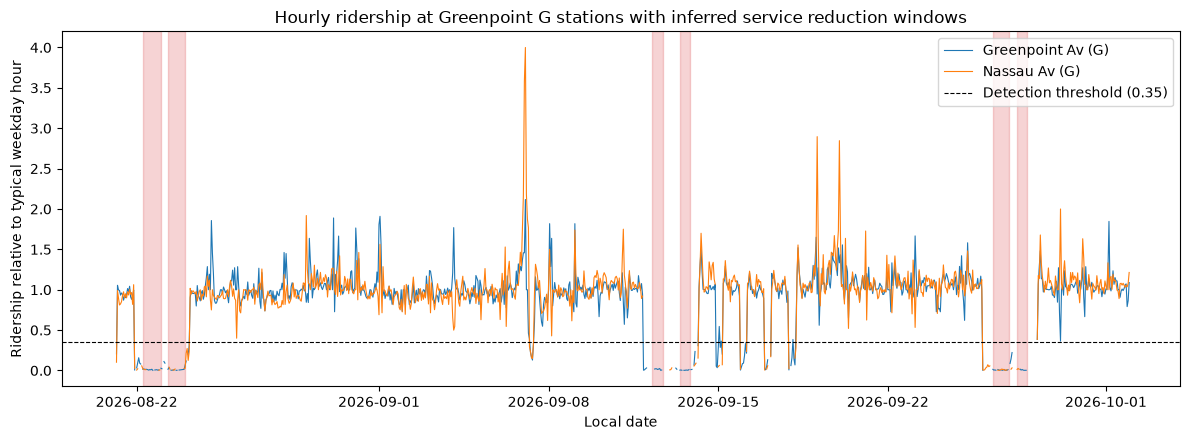

In [10]:
import matplotlib.pyplot as plt

ridership_path = DATA_DIR / "mta_g_station_hourly_ridership_2026.csv"
G_COMPLEX_IDS = [175, 236, 237, 238, 240, 241, 242, 243, 282, 283, 284, 286, 287,
                 288, 289, 290, 291, 292, 606, 608, 629]
if ridership_path.exists():
    g_ridership = pd.read_csv(ridership_path, parse_dates=["transit_timestamp"])
else:
    ridership_rows, offset = [], 0
    id_list = ",".join(f"'{i}'" for i in G_COMPLEX_IDS)
    while True:
        page = fetch_json(
            f"{SODA_ROOT}/5wq4-mkjj.json",
            {
                "$select": "transit_timestamp,station_complex_id,station_complex,sum(ridership) as ridership",
                "$where": (
                    "transit_timestamp >= '2026-08-01T00:00:00' AND transit_timestamp < '2026-10-15T00:00:00' "
                    f"AND station_complex_id in({id_list})"
                ),
                "$group": "transit_timestamp,station_complex_id,station_complex",
                "$order": "transit_timestamp,station_complex_id",
                "$limit": 50_000,
                "$offset": offset,
            },
        )
        ridership_rows.extend(page)
        if len(page) < 50_000:
            break
        offset += 50_000
    if not ridership_rows:
        raise ValueError("MTA hourly ridership returned no rows for the G station complexes.")
    g_ridership = pd.DataFrame(ridership_rows)
    g_ridership["transit_timestamp"] = pd.to_datetime(g_ridership["transit_timestamp"], errors="raise")
    g_ridership["ridership"] = pd.to_numeric(g_ridership["ridership"], errors="raise")
    g_ridership.to_csv(ridership_path, index=False)

ridership_wide = g_ridership.pivot_table(
    index="transit_timestamp", columns="station_complex", values="ridership", aggfunc="sum"
)
detector_stations = ["Greenpoint Av (G)", "Nassau Av (G)"]
holiday_dates = set(pd.to_datetime(["2026-09-04", "2026-09-07", "2026-09-08"]).date)
hour_keys = [ridership_wide.index.dayofweek, ridership_wide.index.hour]
ridership_ratio = pd.DataFrame({
    station: ridership_wide[station]
    / ridership_wide[station].groupby(hour_keys).transform("median").replace(0, np.nan)
    for station in detector_stations
})
low_ridership = (
    (ridership_ratio.max(axis=1) < 0.35)
    & (ridership_wide.index.hour >= 6)
    & ~pd.Series(ridership_wide.index.date, index=ridership_wide.index).isin(holiday_dates)
)

runs = (low_ridership != low_ridership.shift()).cumsum()
raw_windows = [
    (group.index[0], group.index[-1] + pd.Timedelta(hours=1))
    for _, group in low_ridership.groupby(runs)
    if group.iloc[0] and len(group) >= 3
]
merged_windows = []
for start, end in raw_windows:
    if merged_windows and start - merged_windows[-1][1] <= pd.Timedelta(hours=2):
        merged_windows[-1] = (merged_windows[-1][0], end)
    else:
        merged_windows.append((start, end))
g_closure_windows = pd.DataFrame(merged_windows, columns=["start_local", "end_local"])
g_closure_windows["hours"] = (g_closure_windows["end_local"] - g_closure_windows["start_local"]).dt.total_seconds() / 3600
g_closure_windows["median_ratio"] = [
    float(ridership_ratio.loc[s:e - pd.Timedelta(hours=1)].max(axis=1).median())
    for s, e in merged_windows
]
g_closure_windows["in_status_window"] = (
    (g_closure_windows["start_local"] >= "2026-08-21") & (g_closure_windows["start_local"] < "2026-10-02")
)
g_closure_windows.to_csv(PROCESSED_DIR / "g_service_reduction_windows_inferred.csv", index=False)

print(f"Hourly rows for G station complexes: {len(g_ridership):,}")
print(f"Inferred G service reduction windows: {len(g_closure_windows)} "
      f"({int(g_closure_windows['in_status_window'].sum())} inside the station status period)")
display(g_closure_windows.assign(median_ratio=g_closure_windows["median_ratio"].round(2)))

fig, ax = plt.subplots(figsize=(12, 4.5))
visible = ridership_ratio.loc["2026-08-21":"2026-10-01 23:00"]
for station in detector_stations:
    ax.plot(visible.index, visible[station], linewidth=0.8, label=station)
for _, window in g_closure_windows[g_closure_windows["in_status_window"]].iterrows():
    ax.axvspan(window["start_local"], window["end_local"], color="tab:red", alpha=0.2)
ax.axhline(0.35, color="black", linestyle="--", linewidth=0.8, label="Detection threshold (0.35)")
ax.set_ylabel("Ridership relative to typical weekday hour")
ax.set_xlabel("Local date")
ax.set_title("Hourly ridership at Greenpoint G stations with inferred service reduction windows")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


**Figure interpretation.** Each line is hourly ridership divided by the typical level for that weekday and hour, so a value of 1 means a normal hour. Both lines stay near 1 on most days and drop close to 0 together during the shaded red windows, which fall on weekends. A common drop at two stations on the same hours is what a service suspension produces, while a station specific issue or a holiday would not move both lines in this way. These windows are inferred from rider counts, not read from an MTA notice, so they are a proxy for closure hours. The start and end times are approximate to the hour, and low ridership caused by weather or a holiday could also be flagged. They should be checked against the MTA planned work notices before they are used as the exposure label.


### 2.2.1 Confirmed G closure windows from MTA planned service notices

The MTA Weekender notices for August 7 to 10, August 21 to 24, September 11 to 14 and September 25 to 28 each state that G trains do not run between Court Sq and Bedford-Nostrand Avs from 9:45 p.m. Friday to 5 a.m. Monday, because of signal modernization, with free shuttle buses between those stations. The weekends of August 14, August 28 and September 18 do not list this work, and the Labor Day weekend notice lists no G work either. These notices replace the ridership inferred windows as the closure definition for the analysis. The ridership windows are kept as an independent check: if the notices are right, the inferred windows should fall inside them. The notices also list stops skipped on the southern F and G section on some weekends, which are not treated as closures here.


The same notices were read for every weekend from January to July 2026 so that the pre August closure weekends can serve as a longer history for the baseline and for placebo checks. Nine of them state the same Court Sq to Bedford-Nostrand Avs suspension: February 27, March 6, March 13, March 20, March 27, April 17, June 5, June 19 and July 10. Together with the four weekends above, that gives 13 confirmed weekends in 2026. The January 2 to 9, 16 and 23 weekends, the February 6, 13 and 20 weekends, April 3, 10 and 24, May 1, 8, 15, 22 and 29, June 12 and 26, and July 3, 17, 24 and 31 weekends do not list it. The February 27 notice states the 9:45 p.m. Friday to 5 a.m. Monday times in full. For the other pre August weekends only the affected segment was read from the notice summary, and the same times are applied, so the `times_assumed` column marks them.

In [11]:
MTA_WEEKENDER_NOTICES = [
    ("2026-08-07", "https://www.mta.info/article/mta-weekender-august-7-10-2026"),
    ("2026-08-21", "https://www.mta.info/article/mta-weekender-august-21-24-2026"),
    ("2026-09-11", "https://www.mta.info/article/mta-weekender-september-11-14-2026"),
    ("2026-09-25", "https://www.mta.info/article/mta-weekender-september-25-28-2026"),
]
# Each notice states: no G trains between Court Sq and Bedford-Nostrand Avs from 9:45 p.m. Friday to 5 a.m. Monday
confirmed_rows = []
for friday, notice_url in MTA_WEEKENDER_NOTICES:
    start = pd.Timestamp(friday) + pd.Timedelta(hours=21, minutes=45)
    end = pd.Timestamp(friday) + pd.Timedelta(days=3, hours=5)
    confirmed_rows.append({"start_local": start, "end_local": end, "notice_url": notice_url})
g_confirmed_windows = pd.DataFrame(confirmed_rows)

# Whole clock hours fully inside a window: 22:00 Friday through 04:00 Monday
closure_hours = pd.DatetimeIndex(np.concatenate([
    pd.date_range(row.start_local.ceil("h"), row.end_local - pd.Timedelta(hours=1), freq="h").to_numpy()
    for row in g_confirmed_windows.itertuples()
]))
g_confirmed_windows["closure_hours"] = [
    len(pd.date_range(row.start_local.ceil("h"), row.end_local - pd.Timedelta(hours=1), freq="h"))
    for row in g_confirmed_windows.itertuples()
]

inferred_hours = pd.DatetimeIndex(np.concatenate([
    pd.date_range(row.start_local, row.end_local - pd.Timedelta(hours=1), freq="h").to_numpy()
    for row in g_closure_windows.itertuples()
]))
agreement = inferred_hours.isin(closure_hours).mean()
print(f"Confirmed closure hours: {len(closure_hours):,} across {len(g_confirmed_windows)} weekends")
print(f"Share of ridership inferred hours that fall inside a confirmed window: {agreement:.1%}")
print(f"Confirmed weekends with at least one inferred window: "
      f"{sum(any((w.start_local <= i_start < w.end_local) for i_start in g_closure_windows['start_local']) for w in g_confirmed_windows.itertuples())} of {len(g_confirmed_windows)}")
g_confirmed_windows.to_csv(PROCESSED_DIR / "g_service_closures_confirmed.csv", index=False)
display(g_confirmed_windows.drop(columns="notice_url"))


Confirmed closure hours: 220 across 4 weekends
Share of ridership inferred hours that fall inside a confirmed window: 100.0%
Confirmed weekends with at least one inferred window: 4 of 4


,start_local,end_local,closure_hours
0,2026-08-07 21:45:00,2026-08-10 05:00:00,55
1,2026-08-21 21:45:00,2026-08-24 05:00:00,55
2,2026-09-11 21:45:00,2026-09-14 05:00:00,55
3,2026-09-25 21:45:00,2026-09-28 05:00:00,55


In [12]:
PRE_AUGUST_NOTICES = [
    ("2026-02-27", "mta-weekender-february-27-march-2-2026", False),
    ("2026-03-06", "mta-weekender-march-6-9-2026", True),
    ("2026-03-13", "mta-weekender-march-13-16-2026", True),
    ("2026-03-20", "mta-weekender-march-20-23-2026", True),
    ("2026-03-27", "mta-weekender-march-27-30-2026", True),
    ("2026-04-17", "mta-weekender-april-17-20-2026", True),
    ("2026-06-05", "mta-weekender-june-5-8-2026", True),
    ("2026-06-19", "mta-weekender-june-19-22-2026", True),
    ("2026-07-10", "mta-weekender-july-10-13-2026", True),
]
earlier_rows = []
for friday, slug, times_assumed in PRE_AUGUST_NOTICES:
    start = pd.Timestamp(friday) + pd.Timedelta(hours=21, minutes=45)
    end = pd.Timestamp(friday) + pd.Timedelta(days=3, hours=5)
    earlier_rows.append({
        "start_local": start, "end_local": end,
        "notice_url": f"https://www.mta.info/article/{slug}", "times_assumed": times_assumed,
    })
g_confirmed_pre_august = pd.DataFrame(earlier_rows)
g_confirmed_pre_august.to_csv(PROCESSED_DIR / "g_service_closures_confirmed_pre_august.csv", index=False)
print(f"Confirmed G closure weekends before August 2026: {len(g_confirmed_pre_august)}")
print(f"Confirmed G closure weekends in 2026 in total: {len(g_confirmed_pre_august) + len(g_confirmed_windows)}")


Confirmed G closure weekends before August 2026: 9
Confirmed G closure weekends in 2026 in total: 13


**Interpretation of the closure check.** The four notices define 220 closure hours (55 per weekend, from 22:00 Friday to 04:00 Monday). Every one of the ridership inferred hours falls inside a confirmed window, and each confirmed weekend contains at least one inferred window. Two independent sources therefore agree on when G service was cut. The confirmed windows are longer because the ridership rule only flags daytime hours from 06:00 and needs both Greenpoint Av and Nassau Av to be far below normal, while overnight ridership is too small to separate from usual quiet hours. The confirmed windows are used as the closure indicator in the panel. The August 7 to 10 weekend lies before the station status period, so it supports trip and weather analysis but has no availability data.

**Loaded data:** The code reads the extracted January, August and September trip files in chunks and retains hourly departure and arrival counts. It also loads the latest station information snapshot and summarizes station status snapshots by station and local hour. Trip timestamps are kept in local time; status timestamps are converted from UTC to New York time before aggregation. The hourly tables remain separate so differences in their time coverage are visible before they are joined. Station attributes come from the latest snapshot and may differ from historical station locations or capacity.

In [13]:
import pandas as pd

GREENPOINT_LATITUDE = (40.720, 40.740)
GREENPOINT_LONGITUDE = (-73.965, -73.935)

greenpoint_stations = station_info.loc[
    station_info["lat"].between(*GREENPOINT_LATITUDE)
    & station_info["lon"].between(*GREENPOINT_LONGITUDE)
    & station_info["capacity"].gt(0)
].copy()
greenpoint_stations["trip_station_id"] = greenpoint_stations["short_name"].astype("string")
greenpoint_ids = greenpoint_stations["station_id"].dropna().unique()
greenpoint_trip_ids = greenpoint_stations["trip_station_id"].dropna().unique()

greenpoint_trips = trip_demand.rename(
    columns={"station_id": "trip_station_id"}
).loc[lambda frame: frame["trip_station_id"].isin(greenpoint_trip_ids)].merge(
    greenpoint_stations[["station_id", "trip_station_id", "name", "lat", "lon", "capacity"]],
    on="trip_station_id",
    how="left",
    validate="many_to_one",
)
greenpoint_trips["date"] = greenpoint_trips["hour"].dt.normalize()
greenpoint_trips["hour_of_day"] = greenpoint_trips["hour"].dt.hour
greenpoint_trips["weekday"] = greenpoint_trips["hour"].dt.day_name()
greenpoint_trips["day_type"] = greenpoint_trips["hour"].dt.dayofweek.map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)
greenpoint_trips["month"] = greenpoint_trips["hour"].dt.strftime("%Y-%m")

greenpoint_status = station_status_hourly.loc[
    station_status_hourly["station_id"].isin(greenpoint_ids)
].merge(
    greenpoint_stations[["station_id", "name", "lat", "lon", "capacity"]],
    on="station_id",
    how="left",
    validate="many_to_one",
)
greenpoint_status["hour_of_day"] = greenpoint_status["hour"].dt.hour
greenpoint_status["weekday"] = greenpoint_status["hour"].dt.day_name()
greenpoint_status["day_type"] = greenpoint_status["hour"].dt.dayofweek.map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

trip_hours_by_month = (
    trip_demand.assign(month=trip_demand["hour"].dt.strftime("%Y-%m"))
    .groupby("month")[["departures", "arrivals"]]
    .sum()
)
trip_date_min = trip_demand["hour"].min()
trip_date_max = trip_demand["hour"].max()
status_date_min = station_status_hourly["hour"].min()
status_date_max = station_status_hourly["hour"].max()
current_trip_station_ids = set(station_info["short_name"].dropna())
unmatched_trip_stations = trip_station_ids - current_trip_station_ids
duplicate_trip_hour_keys = int(trip_demand.duplicated(["station_id", "hour"]).sum())
duplicate_status_hour_keys = int(station_status_hourly.duplicated(["station_id", "hour"]).sum())
duplicate_current_station_ids = int(station_info["station_id"].duplicated().sum())
trip_status_join = greenpoint_trips.merge(
    greenpoint_status[
        ["station_id", "hour", "bikes_available_mean", "docks_available_mean",
         "zero_bike_snapshots", "zero_dock_snapshots", "snapshot_count"]
    ],
    on=["station_id", "hour"],
    how="outer",
    indicator=True,
    validate="one_to_one",
)

quality_summary = pd.DataFrame(
    [
        ("Trip CSV files read", len(trip_files)),
        ("Raw trip rows read", trip_rows),
        ("Departure records without a station ID", missing_station_ids["departures"]),
        ("Arrival records without a station ID", missing_station_ids["arrivals"]),
        ("Departure timestamps missing or invalid", missing_trip_times["departures"] + invalid_trip_times["departures"]),
        ("Arrival timestamps missing or invalid", missing_trip_times["arrivals"] + invalid_trip_times["arrivals"]),
        ("Trips with nonpositive recorded duration excluded", invalid_trip_duration_rows),
        ("Greenpoint station status snapshots read", status_source_rows),
        ("Missing values in required status fields", sum(status_missing_values.values())),
        ("Status rows with negative bike or dock counts", status_negative_count_rows),
        ("Latest station information snapshot", str(latest_snapshot)),
        ("Duplicate station IDs in latest station snapshot", duplicate_current_station_ids),
        ("Duplicate trip station hour keys", duplicate_trip_hour_keys),
        ("Duplicate status station hour keys", duplicate_status_hour_keys),
        ("Stations in Greenpoint screening rectangle", len(greenpoint_stations)),
        ("Trip station IDs absent from latest station short name crosswalk", len(unmatched_trip_stations)),
        ("Greenpoint trip station hours within status date range", int(greenpoint_trips["hour"].between(status_date_min, status_date_max).sum())),
    ],
    columns=["Check", "Result"],
)

print(f"Greenpoint trip time coverage: {trip_date_min} to {trip_date_max}")
print(f"Greenpoint status time coverage: {status_date_min} to {status_date_max}")
print(f"Greenpoint station screen: {len(greenpoint_stations)} stations")
print(f"Greenpoint trip station hours: {len(greenpoint_trips):,}")
print(f"Greenpoint status station hours: {len(greenpoint_status):,}")
print("\nData quality summary")
display(quality_summary)
print("\nTrip activity by calendar month")
display(trip_hours_by_month)
print("\nGreenpoint trip and status key coverage")
display(trip_status_join["_merge"].value_counts().rename_axis("source coverage").to_frame("station hours"))

Greenpoint trip time coverage: 2025-12-31 17:00:00 to 2026-09-30 23:00:00
Greenpoint status time coverage: 2026-08-21 17:00:00 to 2026-10-01 16:00:00
Greenpoint station screen: 43 stations
Greenpoint trip station hours: 69,170
Greenpoint status station hours: 42,243

Data quality summary


,Check,Result
0,Trip CSV files read,13
1,Raw trip rows read,12045482
2,Departure records without a station ID,7121
3,Arrival records without a station ID,38142
4,Departure timestamps missing or invalid,0
5,Arrival timestamps missing or invalid,0
6,Trips with nonpositive recorded duration excluded,0
7,Greenpoint station status snapshots read,505639
8,Missing values in required status fields,0
9,Status rows with negative bike or dock counts,0



Trip activity by calendar month


,departures,arrivals
month,,
2025-12,5,0
2026-01,51585,51478
2026-07,48,0
2026-08,163315,163050
2026-09,151054,151884



Greenpoint trip and status key coverage


,station hours
source coverage,
left_only,35295
both,33875
right_only,8368


**Data preparation results:** The table above records the current file and quality checks. Records without a station identifier cannot be assigned to a station, so they are excluded from station level counts and reported separately. The spatial screen uses a rectangle and current station information; it is suitable for initial description, not for deciding whether a station was affected by a particular closure. The join coverage table compares trip and status station hours. A missing side of the join means that the source has no matching record for that key; it is not a zero count.

The August and September trip records overlap the station status records from August 21. Weather observations, MTA subway alert updates, and G train stop coordinates are collected from the APIs described in Section 2.2. The alert archive ends on August 11, 2026, while historical station status begins on August 21, 2026. Therefore, alert history does not identify G train closure intervals during the station status period. Those intervals come from the MTA Weekender notices in Section 2.2.1 and are checked against ridership. The figures below describe routine patterns and station inventory; they do not estimate the effect of a subway closure.

## 2.2 Collection and data understanding

The trip archives are stored locally in `datasource` and have already been extracted into month folders. The download cell in Section 2.1 fetches a monthly archive only when it is missing, and this notebook then reads the extracted CSV files directly. Historical station status is stored in date partitioned Parquet files. Station information is stored as dated snapshots. The current GBFS JSON files describe their fetch time and are not a substitute for historical status. The API collection cell retrieves hourly Open Meteo archive weather, MTA subway alert updates, and MTA G train stop coordinates when the corresponding local cache files are absent.

The trip loader selects four fields and reads large CSV files in chunks. Trip records use short station identifiers, while station status uses canonical GBFS identifiers. The station information field `short_name` provides the crosswalk. Trip times are treated as New York local time because the source values have no explicit time zone. Status fetch times are converted from UTC to New York local time. The weather request uses each screened station's coordinates with land cell selection, records the grid coordinates returned by Open Meteo, and reduces repeated station results to unique weather cell and hour records. This follows the station to grid mapping approach in the cited Citi Bike pipeline; its HRRR forecast configuration is not used for historical observations. The resulting station lookup allows each station to be associated with its grid cell. The original source files are left unchanged, and the hourly trip aggregation does not retain individual trip identifiers.

| Source fields | Meaning in the analysis |
| --- | --- |
| `started_at`, `ended_at` | Recorded trip start and end times. |
| `start_station_id`, `end_station_id` | Short identifiers used to assign departures and arrivals. |
| `station_id`, `short_name` | Canonical GBFS key and trip history crosswalk. |
| `name`, `lat`, `lon`, `capacity` | Station description and latest available location and capacity. |
| `fetched_at`, `num_bikes_available`, `num_docks_available` | Status snapshot time, reported bikes, and reported open docks. |
| `temperature_2m`, `precipitation` | Hourly weather at the mapped Open Meteo grid cell; temperature is degrees Celsius and precipitation is millimeters. |
| MTA `date`, `affected`, `header` | Alert update publication time and text fields; they require validation before defining event start or end times. |
| MTA stop coordinates | GTFS stop identifiers and coordinates used to calculate distance to G train stops. |
| Derived station and hour fields | Departure and arrival counts, mean inventory, zero inventory snapshot counts, and snapshot count. |

## 2.3 Data quality checks, results, and cleaning

The loader applies the following checks and transformations:

1. Read four required trip fields in chunks and keep station identifiers as strings so that identifiers with punctuation or leading zeros are preserved. Use the short name crosswalk to focus trip records on the 43 stations in the Greenpoint screening rectangle before parsing their timestamps.
2. Count rows missing a departure or arrival station identifier, then exclude those endpoint rows from station level aggregation. Missing timestamps and timestamps that cannot be parsed are counted separately.
3. Floor valid trip timestamps to the hour. The source timestamps have no explicit offset; the analysis treats the published clock time as New York local time. The convention was checked only for the loaded months. Daylight saving transition dates (March and November) fall in the modeled months and are assumed to be rare enough to ignore here, so they should be reviewed before modeling.
4. Convert the status fetch timestamps from UTC to New York local time. Retain hourly means, the minimum reported open docks, and the number of source snapshots used in each hourly summary.
5. Use the latest station information snapshot for the initial geographic screen. Historical station capacity and location may differ, so event analysis should use station attributes valid at the event date when available.
6. Exclude trips with both timestamps present when the end time is not later than the start time. Match trip station identifiers to the GBFS station identifier through the station information short name field. Match station status directly by GBFS station identifier rather than station name, and report trip identifiers absent from the crosswalk.

### Results of the checks

The checks were run on the seven local trip CSV files, historical status data, and external sources retrieved on October 24, 2026. The table reports measured outcomes and how each was handled.

| Check | Result | Cleaning decision or interpretation |
| --- | --- | --- |
| Trip records read | 6,799,246 | Read in chunks; station level measures were retained for stations in the Greenpoint screen. |
| Departure records without a start station ID | 4,251 | Cannot be assigned to a station; excluded from station level departures and counted in this quality report. |
| Arrival records without an end station ID | 23,375 | Cannot be assigned to a station; excluded from station level arrivals and counted in this quality report. |
| Missing or invalid trip timestamps | 0 | No timestamp rows were excluded for this reason. |
| Trips with end time at or before start time | 0 | No trips were excluded by the duration check. |
| Distinct trip station IDs absent from the latest station crosswalk | 117 | These IDs could not be matched to the latest station list. They are reported for review rather than matched by station name. |
| Screened station status snapshots with missing required values | 0 | No rows were excluded for missing station ID, fetch time, bike count, or dock count. |
| Screened station status snapshots with negative bike or dock counts | 0 | No count corrections or exclusions were required. |
| Duplicate station IDs in the latest station snapshot | 0 | The station information merge did not duplicate station records. |
| Duplicate station by hour keys after aggregation | 0 | Trip and status hourly tables each had unique station and hour keys. |
| MTA subway alert updates retrieved for 2026 | 30,794; latest update August 11 | These are notice updates, not verified service intervals. The archive ends before the station status sample begins. |
| G train stop records retrieved | 21 | Stop coordinates are available for later distance calculations; an alert must first identify which stops lost service. |
| Greenpoint stations linked to weather cells | 43 stations, 1 unique grid cell | The local screen maps all 43 stations to the same returned weather cell. This limits station level weather variation. |
| Hourly weather records | 2,208 for January, August and September combined | Temperature and precipitation are available for the 92 calendar days requested, in New York local time. |

These results support the hourly aggregation for the checks listed, but they do not establish that all source records are error free. The MTA alert date is the notice publication time, not necessarily the disruption start time, and this historical alert feed has no records overlapping the station status sample. This first pass does not assess duplicate ride identifiers, unusually long but positive trip durations, every source quality flag, or whether each station was active throughout the study period. Those checks require additional raw fields or dated station history and should be completed before modeling. Missing trip counts are not changed to zero; zeros are introduced only on the complete calendar grid used for monthly demand plots.

## 2.4 Integration and derived analysis table

Trip records are grouped by start station and start hour for departures, and by end station and end hour for arrivals. The two measures are aligned on station and hour. Status reports are summarized separately at the same grain. The resulting station hour tables can be joined only after their key uniqueness and coverage are checked. Station information adds current location and capacity for an initial screen. Weather values can be joined by local hour and the station to weather cell lookup, after checking coverage. MTA alert updates are collected, but their text must be converted into validated event intervals before they can be used as a disruption indicator. Stop coordinates support a stated distance rule once affected stops and event intervals are known.

A join will be checked for unintended row multiplication, unmatched station identifiers, and timestamps outside source coverage. The alert's publication time will not be treated as the disruption start time unless the source confirms that interpretation. Any method used to extract service times from alert text will be validated against known events.

## 2.5 Disruption exposure and analysis ready dataset

The confirmed closure windows describe when service was reduced, but the model also needs to know which stations are exposed. Two steps turn the windows into model inputs. First, the affected segment is taken from the MTA notices: no G trains run between Court Sq and Bedford-Nostrand Avs, which covers eight G stops (Court Sq, 21 St, Greenpoint Av, Nassau Av, Metropolitan Av, Broadway, Flushing Av and Myrtle-Willoughby Avs). The segment is checked against hourly ridership: a G station complex is flagged by ridership when its median ridership inside the closure windows falls below 35 percent of its typical level for that weekday and hour. Second, each Greenpoint station is assigned the distance in miles to its nearest affected stop, and a station is exposed when that distance is at most a quarter mile, which is the exposure rule in the project proposal.


In [14]:
segment_complexes = g_ridership[["station_complex_id", "station_complex"]].drop_duplicates().copy()
segment_complexes["station_complex_id"] = segment_complexes["station_complex_id"].astype(str)

typical_ridership = ridership_wide.groupby(hour_keys).transform("median").replace(0, np.nan)
all_ratio = ridership_wide / typical_ridership
in_window_ratio = all_ratio.loc[all_ratio.index.isin(closure_hours)].median()
outside_ratio = all_ratio.loc[~all_ratio.index.isin(closure_hours)].median()
segment_table = segment_complexes.merge(
    pd.DataFrame({
        "station_complex": in_window_ratio.index,
        "ratio_inside_windows": in_window_ratio.to_numpy(),
        "ratio_outside_windows": outside_ratio.to_numpy(),
    }),
    on="station_complex",
)
segment_table["affected"] = segment_table["ratio_inside_windows"] < 0.35
segment_table = segment_table.sort_values("ratio_inside_windows").reset_index(drop=True)
affected_complex_ids = set(segment_table.loc[segment_table["affected"], "station_complex_id"])

# The MTA notices name the segment: no G trains between Court Sq (G22) and Bedford-Nostrand Avs (G33)
g_line_stops = mta_g_stops[mta_g_stops["gtfs_stop_id"].str.startswith("G")].copy()
g_line_stops["stop_number"] = g_line_stops["gtfs_stop_id"].str[1:].astype(int)
segment_stop_ids = g_line_stops.loc[g_line_stops["stop_number"].between(22, 32), "gtfs_stop_id"]
notice_complex_ids = set(
    mta_g_stops.loc[mta_g_stops["gtfs_stop_id"].isin(segment_stop_ids), "complex_id"].astype(str)
)
segment_table["named_in_notice"] = segment_table["station_complex_id"].isin(notice_complex_ids)
affected_stops = mta_g_stops[mta_g_stops["gtfs_stop_id"].isin(segment_stop_ids)].copy()
mta_g_stops["affected_segment"] = mta_g_stops["gtfs_stop_id"].isin(segment_stop_ids)

station_points = greenpoint_stations[
    ["station_id", "name", "lat", "lon", "capacity"]
].drop_duplicates("station_id")
station_stop_pairs = station_points.merge(
    affected_stops[["gtfs_stop_id", "stop_name", "gtfs_latitude", "gtfs_longitude"]], how="cross"
)
station_stop_pairs["distance_miles"] = haversine_km(
    station_stop_pairs["lat"], station_stop_pairs["lon"],
    station_stop_pairs["gtfs_latitude"], station_stop_pairs["gtfs_longitude"],
) / 1.609344
station_exposure = (
    station_stop_pairs.sort_values("distance_miles")
    .drop_duplicates("station_id")
    .rename(columns={"stop_name": "nearest_affected_stop", "distance_miles": "nearest_affected_stop_miles"})
    .drop(columns=["gtfs_stop_id", "gtfs_latitude", "gtfs_longitude"])
    .reset_index(drop=True)
)
station_exposure["exposed_station"] = station_exposure["nearest_affected_stop_miles"] <= 0.25
station_exposure["distance_band"] = pd.cut(
    station_exposure["nearest_affected_stop_miles"],
    [0, 0.25, 0.5, np.inf],
    labels=["Within 0.25 mile", "0.25 to 0.5 mile", "Beyond 0.5 mile"],
    include_lowest=True,
)
station_exposure.to_csv(PROCESSED_DIR / "greenpoint_station_exposure.csv", index=False)

print(f"Confirmed closure hours: {len(closure_hours):,}")
print(f"G complexes with a ridership collapse inside the confirmed windows: {len(affected_complex_ids)} of {len(segment_table)}\nG complexes named in the notices: {len(notice_complex_ids)}; ridership flagged complexes also named in the notices: {len(affected_complex_ids & notice_complex_ids)} of {len(affected_complex_ids)}")
display(segment_table.assign(
    ratio_inside_windows=segment_table["ratio_inside_windows"].round(3),
    ratio_outside_windows=segment_table["ratio_outside_windows"].round(3),
))
print("Affected segment stops: " + ", ".join(affected_stops.sort_values("gtfs_stop_id")["stop_name"]))
print(f"Stations within 0.25 mile of an affected stop: {int(station_exposure['exposed_station'].sum())} of {len(station_exposure)}")
display(station_exposure["distance_band"].value_counts().sort_index().rename("stations").to_frame())


Confirmed closure hours: 220
G complexes with a ridership collapse inside the confirmed windows: 6 of 21
G complexes named in the notices: 8; ridership flagged complexes also named in the notices: 6 of 6


,station_complex_id,station_complex,ratio_inside_windows,ratio_outside_windows,affected,named_in_notice
0,283,Greenpoint Av (G),0.010,1.001,True,True
1,284,Nassau Av (G),0.013,1.000,True,True
2,286,Broadway (G),0.017,1.000,True,True
3,288,Myrtle-Willoughby Avs (G),0.018,1.000,True,True
4,282,21 St (G),0.024,1.000,True,True
5,287,Flushing Av (G),0.048,1.000,True,True
6,291,Clinton-Washington Avs (G),0.812,1.000,False,False
7,292,Fulton St (G),0.816,1.008,False,False
8,290,Classon Av (G),0.857,1.000,False,False
9,629,"Metropolitan Av/Lorimer St (G,L)",0.861,1.000,False,True


Affected segment stops: Court Sq, 21 St, Greenpoint Av, Nassau Av, Metropolitan Av, Broadway, Flushing Av, Myrtle-Willoughby Avs
Stations within 0.25 mile of an affected stop: 14 of 43


,stations
distance_band,
Within 0.25 mile,14
0.25 to 0.5 mile,21
Beyond 0.5 mile,8


**Interpretation of the exposure definition.** Six of the 21 G complexes (Greenpoint Av, Nassau Av, Broadway, Myrtle-Willoughby Avs, 21 St and Flushing Av) keep only 1 to 5 percent of their usual entries inside the confirmed windows, while the two transfer complexes stay near normal. All six are also named in the MTA notices, so the ridership check agrees with the notices. The notices name eight stops. The two extra stops, Court Sq and Metropolitan Av, are transfer complexes (ratios 1.09 and 0.86) whose ridership is carried by other lines, so ridership alone cannot flag them. The notice based segment is used for exposure. Of the 43 Citi Bike stations, 14 lie within 0.25 mile of an affected stop, 21 between 0.25 and 0.5 mile, and 8 beyond 0.5 mile. The 14 stations form the exposed group. A limit is that distance to a stop is a proxy for being served by that stop, and riders may walk farther than a quarter mile.

### Station hour panel

The analysis table has one row per station and clock hour from August 1 to September 30, 2026. Trip counts are observed for the whole period, so a station hour with no recorded trip is a true zero. Station status begins on August 21, so earlier rows keep missing availability values instead of zeros, and the `status_observed` flag marks the rows that have them. Weather is joined by hour, exposure and closure flags are added, and calendar and lag features are created. The table is checked for duplicate keys and the expected row count, then saved to `datasource/processed/analysis_station_hour_panel.parquet`.


In [15]:
PANEL_START = pd.Timestamp("2026-08-01 00:00")
PANEL_END = pd.Timestamp("2026-09-30 23:00")
TRIP_COVERAGE_START = pd.Timestamp("2026-08-01 00:00")

panel_hours = pd.date_range(PANEL_START, PANEL_END, freq="h")
panel = pd.MultiIndex.from_product(
    [station_exposure["station_id"].astype(str), panel_hours], names=["station_id", "hour"]
).to_frame(index=False)

trip_columns = greenpoint_trips[["station_id", "hour", "departures", "arrivals"]].copy()
trip_columns["station_id"] = trip_columns["station_id"].astype(str)
status_columns = greenpoint_status[
    ["station_id", "hour", "bikes_available_mean", "docks_available_mean",
     "zero_bike_snapshots", "zero_dock_snapshots", "snapshot_count"]
].copy()
status_columns["station_id"] = status_columns["station_id"].astype(str)
weather_columns = greenpoint_weather[["time", "temperature_2m", "precipitation"]].rename(
    columns={"time": "hour"}
)

panel = (
    panel.merge(trip_columns, on=["station_id", "hour"], how="left", validate="one_to_one")
    .merge(status_columns, on=["station_id", "hour"], how="left", validate="one_to_one")
    .merge(weather_columns, on="hour", how="left", validate="many_to_one")
    .merge(
        station_exposure[["station_id", "name", "lat", "lon", "capacity",
                          "nearest_affected_stop", "nearest_affected_stop_miles",
                          "exposed_station", "distance_band"]].assign(
            station_id=lambda frame: frame["station_id"].astype(str)),
        on="station_id", how="left", validate="many_to_one",
    )
)

panel["trip_observed"] = panel["hour"] >= TRIP_COVERAGE_START
panel["status_observed"] = panel["snapshot_count"].notna()
for column in ("departures", "arrivals"):
    panel[column] = panel[column].where(~panel["trip_observed"], panel[column].fillna(0))

panel["hour_of_day"] = panel["hour"].dt.hour
panel["day_of_week"] = panel["hour"].dt.dayofweek
panel["is_weekend"] = panel["day_of_week"] >= 5
panel["hour_sin"] = np.sin(2 * np.pi * panel["hour_of_day"] / 24)
panel["hour_cos"] = np.cos(2 * np.pi * panel["hour_of_day"] / 24)
panel["g_closure_hour"] = panel["hour"].isin(closure_hours)
panel["exposed_closure_hour"] = panel["g_closure_hour"] & panel["exposed_station"]
panel["precipitation_any"] = panel["precipitation"] > 0
panel["net_flow"] = panel["arrivals"] - panel["departures"]
panel["zero_dock_share"] = panel["zero_dock_snapshots"] / panel["snapshot_count"]
panel["zero_bike_share"] = panel["zero_bike_snapshots"] / panel["snapshot_count"]
panel = panel.sort_values(["station_id", "hour"]).reset_index(drop=True)
for lag in (24, 168):
    panel[f"departures_lag_{lag}h"] = panel.groupby("station_id")["departures"].shift(lag)
panel["total_trips"] = panel["departures"] + panel["arrivals"]

if panel.duplicated(["station_id", "hour"]).any():
    raise ValueError("The analysis panel contains duplicate station hour keys.")
expected_rows = len(station_exposure) * len(panel_hours)
if len(panel) != expected_rows:
    raise ValueError(f"Panel has {len(panel):,} rows, expected {expected_rows:,}.")

panel.to_parquet(PROCESSED_DIR / "analysis_station_hour_panel.parquet", index=False)

panel_checks = pd.DataFrame([
    ("Stations", panel["station_id"].nunique()),
    ("Hours", len(panel_hours)),
    ("Station hour rows", len(panel)),
    ("Rows with observed trip counts (August and September)", int(panel["trip_observed"].sum())),
    ("Rows with status snapshots", int(panel["status_observed"].sum())),
    ("Rows missing weather", int(panel["temperature_2m"].isna().sum())),
    ("Closure hours (all stations)", int(panel["g_closure_hour"].sum())),
    ("Closure station hours at exposed stations", int(panel["exposed_closure_hour"].sum())),
    ("Closure station hours with observed trips", int((panel["g_closure_hour"] & panel["trip_observed"]).sum())),
], columns=["Check", "Result"])
missing_by_column = panel.isna().sum().loc[lambda counts: counts.gt(0)].rename("missing values").to_frame()
missing_by_column["share"] = (missing_by_column["missing values"] / len(panel)).round(3)

print(f"Analysis panel saved: {panel.shape[0]:,} rows and {panel.shape[1]} columns")
display(panel_checks)
display(missing_by_column)


Analysis panel saved: 62,952 rows and 35 columns


,Check,Result
0,Stations,43
1,Hours,1464
2,Station hour rows,62952
3,Rows with observed trip counts (August and Sep...,62952
4,Rows with status snapshots,41512
5,Rows missing weather,0
6,Closure hours (all stations),9460
7,Closure station hours at exposed stations,3080
8,Closure station hours with observed trips,9460


,missing values,share
bikes_available_mean,21440,0.341
docks_available_mean,21440,0.341
zero_bike_snapshots,21440,0.341
zero_dock_snapshots,21440,0.341
snapshot_count,21440,0.341
zero_dock_share,21440,0.341
zero_bike_share,21440,0.341
departures_lag_24h,1032,0.016
departures_lag_168h,7224,0.115


**Interpretation of the analysis panel.** The panel has one row per station and hour: 43 stations over 1,464 hours gives 62,952 rows, and every row has observed trip counts and weather. Status snapshots exist for 41,512 rows (66 percent). The 21,440 rows without status are all hours before August 21 and share the same missingness pattern, so availability features can only be modeled on the later period. The lag features lose 1,032 rows (24 hour lag) and 7,224 rows (168 hour lag) at the start of the series. The 220 confirmed closure hours give 9,460 closure station hours, of which 3,080 are at the 14 exposed stations. This panel rests on four closure weekends, and the extended panel in Section 2.6 widens that to 13.

## 2.6 Extended datasets for modeling

The analysis panel in Section 2.5 covers only the Greenpoint stations in August and September 2026. The project proposal needs more than that: a shutdown table, demand for corridor and control stations, a baseline built from recent normal weeks, a demand proxy from station status, and a 2024 shutdown check. This section builds those tables from the trip months downloaded in Section 2.1 and saves each one to the `datasource` folder.

| Table | Variable | File | Purpose |
|---|---|---|---|
| Shutdown table | `mta_subway_shutdowns` | `mta_subway_shutdowns.csv` | One row per shutdown event and affected G stop, with the Citi Bike stations within 0.25 mile |
| Station sets | `model_stations` | `model_station_sets.csv` | Corridor stations and a random sample of control stations |
| Hourly trips | `trip_hourly` | `trip_hourly_model_stations.parquet` | Departures and arrivals per station hour, May to September 2024 and January to September 2026 |
| Extended panel | `panel_extended` | `analysis_station_hour_panel_extended.parquet` | Demand, weather, calendar, shutdown flags, baseline, profile, split and status proxy |
| Accuracy check | `baseline_accuracy` | `baseline_accuracy_by_month.csv` | Error of the baseline by month and station group |
| Effect screening | `event_effect_table` | `shutdown_effect_screening.csv` | Demand at exposed versus control stations during shutdowns and placebo weekends |

In [16]:
EXTENDED_MONTHS = (
    "202405", "202406", "202407", "202408", "202409",
    "202601", "202602", "202603", "202604", "202605", "202606", "202607", "202608", "202609",
)
CONTROL_MIN_MILES = 3.0
CONTROL_SAMPLE_SIZE = 60
SELECTION_SEED = 622
EXPOSURE_MILES = 0.25

all_stations = station_info.loc[
    station_info["capacity"].gt(0) & station_info["short_name"].notna(),
    ["station_id", "short_name", "name", "lat", "lon", "capacity"],
].drop_duplicates("short_name").reset_index(drop=True)
g_only_stops = mta_g_stops.loc[
    mta_g_stops["gtfs_stop_id"].str.startswith("G"),
    ["gtfs_stop_id", "stop_name", "gtfs_latitude", "gtfs_longitude"],
].copy()
all_pairs = all_stations[["short_name", "lat", "lon"]].merge(g_only_stops, how="cross")
all_pairs["distance_miles"] = haversine_km(
    all_pairs["lat"], all_pairs["lon"], all_pairs["gtfs_latitude"], all_pairs["gtfs_longitude"]
) / 1.609344
all_stations["miles_to_nearest_g_stop"] = all_stations["short_name"].map(
    all_pairs.groupby("short_name")["distance_miles"].min()
)

in_corridor = (
    all_stations["short_name"].isin(greenpoint_stations["short_name"])
    | all_stations["miles_to_nearest_g_stop"].le(EXPOSURE_MILES)
)
control_pool = all_stations[~in_corridor & all_stations["miles_to_nearest_g_stop"].gt(CONTROL_MIN_MILES)]
control_sample = control_pool.sample(CONTROL_SAMPLE_SIZE, random_state=SELECTION_SEED)
all_stations["station_group"] = np.where(in_corridor, "corridor", None)
all_stations.loc[control_sample.index, "station_group"] = "control"
model_stations = all_stations[all_stations["station_group"].notna()].reset_index(drop=True)
model_pairs = all_pairs[all_pairs["short_name"].isin(model_stations["short_name"])]

# One row per shutdown event. The 2024 phases are taken from the MTA notice text (June 28 to September 3, 2024).
event_rows = []
for row in g_confirmed_pre_august.itertuples():
    event_rows.append(dict(event_type="2026 weekend closure", start_local=row.start_local, end_local=row.end_local,
                           stop_ids=list(segment_stop_ids), source=row.notice_url, times_assumed=row.times_assumed))
for row in g_confirmed_windows.itertuples():
    event_rows.append(dict(event_type="2026 weekend closure", start_local=row.start_local, end_local=row.end_local,
                           stop_ids=list(segment_stop_ids), source=row.notice_url, times_assumed=False))
phase_notice = "MTA summer 2024 G line service change (phase dates from the MTA notice text)"
for label, start, end, stops in [
    ("2024 phase 1", "2024-06-28", "2024-07-05", ["G22", "G24", "G26"]),
    ("2024 phase 2", "2024-07-05", "2024-08-12", list(segment_stop_ids)),
    ("2024 phase 3", "2024-08-12", "2024-09-03", ["G34", "G35", "G36"]),
]:
    event_rows.append(dict(event_type=label, start_local=pd.Timestamp(start), end_local=pd.Timestamp(end),
                           stop_ids=stops, source=phase_notice, times_assumed=True))
shutdown_events = pd.DataFrame(event_rows).sort_values("start_local").reset_index(drop=True)
shutdown_events["event_id"] = [f"E{index + 1:02d}" for index in shutdown_events.index]

event_station_exposure = []
shutdown_rows = []
for event in shutdown_events.itertuples():
    pairs = model_pairs[model_pairs["gtfs_stop_id"].isin(event.stop_ids)]
    nearest = pairs.groupby("short_name")["distance_miles"].min()
    event_station_exposure.append(pd.DataFrame({
        "event_id": event.event_id, "short_name": nearest.index,
        "distance_to_event_miles": nearest.to_numpy(),
        "event_exposed": (nearest <= EXPOSURE_MILES).to_numpy(),
    }))
    for stop in g_only_stops[g_only_stops["gtfs_stop_id"].isin(event.stop_ids)].itertuples():
        near = pairs[(pairs["gtfs_stop_id"] == stop.gtfs_stop_id) & pairs["distance_miles"].le(EXPOSURE_MILES)]
        shutdown_rows.append(dict(
            event_id=event.event_id, event_type=event.event_type, line="G",
            gtfs_stop_id=stop.gtfs_stop_id, stop_name=stop.stop_name,
            latitude=stop.gtfs_latitude, longitude=stop.gtfs_longitude,
            start_local=event.start_local, end_local=event.end_local,
            times_assumed=event.times_assumed, source=event.source,
            citi_bike_stations_within_quarter_mile=near["short_name"].nunique(),
            citi_bike_station_ids=";".join(sorted(near["short_name"].unique())),
        ))
event_station_exposure = pd.concat(event_station_exposure, ignore_index=True)
mta_subway_shutdowns = pd.DataFrame(shutdown_rows)
mta_subway_shutdowns.to_csv(PROCESSED_DIR / "mta_subway_shutdowns.csv", index=False)
model_stations.to_csv(PROCESSED_DIR / "model_station_sets.csv", index=False)

print(f"Citi Bike stations with a trip station code and capacity: {len(all_stations):,}")
print(f"Corridor stations: {int((model_stations['station_group'] == 'corridor').sum())}; "
      f"control stations sampled: {int((model_stations['station_group'] == 'control').sum())} "
      f"from a pool of {len(control_pool):,} stations more than {CONTROL_MIN_MILES:.0f} miles from any G stop")
print(f"Shutdown events: {len(shutdown_events)}; shutdown table rows (event by stop): {len(mta_subway_shutdowns)}")
display(shutdown_events.assign(stops=shutdown_events["stop_ids"].str.len())
        .groupby("event_type").agg(events=("event_id", "size"), stops=("stops", "max"),
                                   first_start=("start_local", "min"), last_end=("end_local", "max")))
display(mta_subway_shutdowns.groupby("event_type")["citi_bike_stations_within_quarter_mile"].agg(["min", "max"]))

Citi Bike stations with a trip station code and capacity: 2,471
Corridor stations: 94; control stations sampled: 60 from a pool of 1,048 stations more than 3 miles from any G stop
Shutdown events: 16; shutdown table rows (event by stop): 118


,events,stops,first_start,last_end
event_type,,,,
2024 phase 1,1,3,2024-06-28 00:00:00,2024-07-05 00:00:00
2024 phase 2,1,8,2024-07-05 00:00:00,2024-08-12 00:00:00
2024 phase 3,1,3,2024-08-12 00:00:00,2024-09-03 00:00:00
2026 weekend closure,13,8,2026-02-27 21:45:00,2026-09-28 05:00:00


,min,max
event_type,,
2024 phase 1,7,7
2024 phase 2,4,7
2024 phase 3,4,8
2026 weekend closure,4,7


**Station sets and shutdown events.** A station is in the corridor group when it is in the Greenpoint screening area or within 0.25 mile of any G stop. That gives 94 corridor stations. The control group is a random sample of 60 stations drawn with seed 622 from the 1,048 stations that are more than 3 miles from every G stop. These stations are unaffected by G service, so they absorb citywide shifts such as weather, season and holidays.

The shutdown table has 16 events and 118 event by stop rows: the 13 confirmed 2026 weekends (Section 2.2.1) and the three phases of the 2024 shutdown. For 2024 the phases are Court Sq to Nassau Av (June 28 to July 5), Court Sq to Bedford-Nostrand Avs (July 5 to August 12) and Bedford-Nostrand Avs to Church Av (August 12 to September 3), taken from the MTA notice text. Stops closed in each phase are Court Sq, 21 St and Greenpoint Av for phase 1, the eight stops of the 2026 segment for phase 2, and Classon Av, Clinton-Washington Avs and Fulton St for phase 3. Only the G line stops are listed, because the shared F stops keep other service. The 2024 windows use whole days because the exact start and end times were not available, and are marked `times_assumed`. Eight of the nine earlier 2026 weekends also carry assumed times. Citi Bike stations are counted within 0.25 mile of each stop, the same exposure radius used in Section 2.5.

In [17]:
EXTENDED_TRIP_PATH = PROCESSED_DIR / "trip_hourly_model_stations.parquet"
if not EXTENDED_TRIP_PATH.exists():
    selected_codes = set(model_stations["short_name"])
    flow_parts = {"departures": [], "arrivals": []}
    rows_read = 0
    for month in EXTENDED_MONTHS:
        month_files = sorted((DATA_DIR / f"{month}-citibike-tripdata").glob("*.csv"))
        if not month_files:
            raise FileNotFoundError(f"No extracted trip CSV files for {month}. Run the download cell first.")
        for trip_file in month_files:
            print(f"Reading {trip_file}", flush=True)
            for chunk in pd.read_csv(
                trip_file, usecols=TRIP_COLUMNS, chunksize=500_000,
                dtype={"start_station_id": "string", "end_station_id": "string"},
            ):
                rows_read += len(chunk)
                chunk = chunk[chunk["start_station_id"].isin(selected_codes) | chunk["end_station_id"].isin(selected_codes)]
                starts = pd.to_datetime(chunk["started_at"], format="ISO8601", errors="coerce")
                ends = pd.to_datetime(chunk["ended_at"], format="ISO8601", errors="coerce")
                valid = starts.notna() & ends.notna() & ends.gt(starts)
                for flow, code_column, times in (("departures", "start_station_id", starts), ("arrivals", "end_station_id", ends)):
                    keep = valid & chunk[code_column].isin(selected_codes)
                    counts = (
                        pd.DataFrame({"short_name": chunk.loc[keep, code_column], "hour": times[keep].dt.floor("h")})
                        .groupby(["short_name", "hour"], observed=True).size()
                    )
                    flow_parts[flow].append(counts)
    parts = [pd.concat(flow_parts[flow]).groupby(level=[0, 1]).sum().rename(flow) for flow in flow_parts]
    trip_hourly = (
        pd.concat(parts, axis=1).fillna(0).astype("int64").rename_axis(["short_name", "hour"]).reset_index()
    )
    trip_hourly["short_name"] = trip_hourly["short_name"].astype(str)
    trip_hourly.to_parquet(EXTENDED_TRIP_PATH, index=False)
    print(f"Trip rows read in this pass: {rows_read:,}")
trip_hourly = pd.read_parquet(EXTENDED_TRIP_PATH)
trip_hourly["month"] = trip_hourly["hour"].dt.to_period("M").astype(str)
coverage = trip_hourly.groupby("month").agg(
    stations=("short_name", "nunique"), station_hours=("short_name", "size"),
    departures=("departures", "sum"), arrivals=("arrivals", "sum"),
)
print(f"Hourly trip table for the model stations: {len(trip_hourly):,} station hours")
display(coverage)

Hourly trip table for the model stations: 917,942 station hours


,stations,station_hours,departures,arrivals
month,,,,
2024-04,16,16,22,0
2024-05,126,62296,225787,227055
2024-06,130,65597,283988,285531
2024-07,131,69307,301904,303709
2024-08,134,69365,290428,292015
2024-09,135,69313,301099,301149
2025-12,17,17,23,0
2026-01,141,50600,110692,109461
2026-02,141,41930,75469,75326


**Hourly trips.** One pass over 58.4 million trip records (14 months) kept the trips that start or end at the 154 model stations (one control station, JC124, has no trips, so 153 stations remain) and counted departures and arrivals per station hour. Trips with a missing time or a nonpositive duration were dropped, as in Section 2.1. The result has 917,942 station hours. The first table shows that each month has between 126 and 149 active stations, and that January and February 2026 have lower volumes than summer months, which is the expected seasonal pattern. The few records dated April 2024 and December 2025 are trips whose end time falls in the next month file, and they lie outside the panel periods. The cached parquet file means this pass runs only once.

In [18]:
from pandas.tseries.holiday import USFederalHolidayCalendar

EXTENDED_PERIODS = [
    ("2024", pd.Timestamp("2024-05-01 00:00"), pd.Timestamp("2024-09-30 23:00")),
    ("2026", pd.Timestamp("2026-01-01 00:00"), pd.Timestamp("2026-09-30 23:00")),
]
period_frames = []
for period, start, end in EXTENDED_PERIODS:
    active = trip_hourly.loc[trip_hourly["hour"].between(start, end), "short_name"].unique()
    stations_in_period = model_stations[model_stations["short_name"].isin(active)]
    frame = pd.MultiIndex.from_product(
        [stations_in_period["short_name"], pd.date_range(start, end, freq="h")], names=["short_name", "hour"]
    ).to_frame(index=False)
    frame["period"] = period
    period_frames.append(frame)
panel_extended = pd.concat(period_frames, ignore_index=True)
panel_extended = (
    panel_extended
    .merge(trip_hourly[["short_name", "hour", "departures", "arrivals"]], on=["short_name", "hour"], how="left", validate="one_to_one")
    .merge(model_stations[["short_name", "station_id", "name", "lat", "lon", "capacity", "station_group", "miles_to_nearest_g_stop"]],
           on="short_name", how="left", validate="many_to_one")
)
panel_extended[["departures", "arrivals"]] = panel_extended[["departures", "arrivals"]].fillna(0).astype("int64")

weather_all = (
    pd.concat([greenpoint_weather[["time", "temperature_2m", "precipitation"]],
               extended_weather[["time", "temperature_2m", "precipitation"]]])
    .drop_duplicates("time").rename(columns={"time": "hour"})
)
panel_extended = panel_extended.merge(weather_all, on="hour", how="left", validate="many_to_one")

holiday_dates = USFederalHolidayCalendar().holidays("2024-01-01", "2026-12-31")
panel_extended["hour_of_day"] = panel_extended["hour"].dt.hour
panel_extended["day_of_week"] = panel_extended["hour"].dt.dayofweek
panel_extended["is_weekend"] = panel_extended["day_of_week"] >= 5
panel_extended["is_holiday"] = panel_extended["hour"].dt.normalize().isin(holiday_dates)
panel_extended["hour_sin"] = np.sin(2 * np.pi * panel_extended["hour_of_day"] / 24)
panel_extended["hour_cos"] = np.cos(2 * np.pi * panel_extended["hour_of_day"] / 24)
panel_extended["precipitation_any"] = panel_extended["precipitation"] > 0
panel_extended["total_trips"] = panel_extended["departures"] + panel_extended["arrivals"]
panel_extended["net_flow"] = panel_extended["arrivals"] - panel_extended["departures"]

# Shutdown flags: each event covers the whole clock hours that fall inside its window.
event_hours = pd.concat([
    pd.DataFrame({"event_id": event.event_id, "event_type": event.event_type,
                  "hour": pd.date_range(event.start_local.ceil("h"), event.end_local - pd.Timedelta(hours=1), freq="h")})
    for event in shutdown_events.itertuples()
], ignore_index=True)
panel_extended = (
    panel_extended
    .merge(event_hours, on="hour", how="left", validate="many_to_one")
    .merge(event_station_exposure[["event_id", "short_name", "distance_to_event_miles", "event_exposed"]],
           on=["event_id", "short_name"], how="left", validate="many_to_one")
)
panel_extended["g_closure_hour"] = panel_extended["event_id"].notna()
panel_extended["event_exposed"] = panel_extended["event_exposed"].fillna(False).astype(bool)
panel_extended["exposed_closure_hour"] = panel_extended["g_closure_hour"] & panel_extended["event_exposed"]

# Stations near the 2026 segment, used for placebo comparisons, and near any 2024 phase stop
segment_exposed = set(event_station_exposure.loc[
    event_station_exposure["event_id"].isin(shutdown_events.loc[shutdown_events["event_type"].eq("2026 weekend closure"), "event_id"])
    & event_station_exposure["event_exposed"], "short_name"])
exposed_2024 = set(event_station_exposure.loc[
    event_station_exposure["event_id"].isin(shutdown_events.loc[shutdown_events["event_type"].str.startswith("2024"), "event_id"])
    & event_station_exposure["event_exposed"], "short_name"])
panel_extended["exposed_station"] = panel_extended["short_name"].isin(segment_exposed)
panel_extended["exposed_station_2024"] = panel_extended["short_name"].isin(exposed_2024)

# Placebo weekends: the same Friday 22:00 to Monday 04:00 window on weekends without a known closure
weekend_window = (
    ((panel_extended["day_of_week"] == 4) & (panel_extended["hour_of_day"] >= 22))
    | panel_extended["day_of_week"].isin([5, 6])
    | ((panel_extended["day_of_week"] == 0) & (panel_extended["hour_of_day"] < 4))
)
panel_extended["placebo_weekend_hour"] = weekend_window & ~panel_extended["g_closure_hour"] & panel_extended["period"].eq("2026")

# Chronological split indicator for the 2026 data, with 2024 held out for the shutdown validation
month_number = panel_extended["hour"].dt.month
panel_extended["split"] = np.select(
    [panel_extended["period"].eq("2024"), month_number.le(6), month_number.eq(7)],
    ["validation_2024", "train", "validation"], default="test",
)

# Availability features exist only where the status feed was collected (Greenpoint, Aug 21 to Sep 30, 2026)
status_columns_keep = ["station_id", "hour", "bikes_available_mean", "docks_available_mean",
                       "zero_bike_snapshots", "zero_dock_snapshots", "snapshot_count"]
panel_extended = panel_extended.merge(
    panel[status_columns_keep].assign(station_id=lambda frame: frame["station_id"].astype(str)),
    on=["station_id", "hour"], how="left", validate="many_to_one",
)
panel_extended["status_observed"] = panel_extended["snapshot_count"].notna()
panel_extended = panel_extended.sort_values(["short_name", "period", "hour"]).reset_index(drop=True)

# A station is active from its first to its last recorded trip within each period. Hours outside that span
# are not zero demand: the station had not opened yet or had been removed, so they are flagged and excluded later.
trip_span = panel_extended.loc[panel_extended["total_trips"].gt(0)].groupby(["short_name", "period"])["hour"].agg(first_trip="min", last_trip="max")
panel_extended = panel_extended.merge(trip_span.reset_index(), on=["short_name", "period"], how="left")
panel_extended["station_active"] = panel_extended["hour"].between(panel_extended["first_trip"], panel_extended["last_trip"])
panel_extended = panel_extended.drop(columns=["first_trip", "last_trip"])

if panel_extended.duplicated(["short_name", "hour"]).any():
    raise ValueError("The extended panel contains duplicate station hour keys.")
extended_checks = pd.DataFrame([
    ("Stations", panel_extended["short_name"].nunique()),
    ("Station hour rows", len(panel_extended)),
    ("Rows in 2024 / 2026", f"{int(panel_extended['period'].eq('2024').sum()):,} / {int(panel_extended['period'].eq('2026').sum()):,}"),
    ("Rows missing weather", int(panel_extended["temperature_2m"].isna().sum())),
    ("Closure station hours", int(panel_extended["g_closure_hour"].sum())),
    ("Closure station hours at exposed stations", int(panel_extended["exposed_closure_hour"].sum())),
    ("Placebo weekend station hours", int(panel_extended["placebo_weekend_hour"].sum())),
    ("Holiday station hours", int(panel_extended["is_holiday"].sum())),
    ("Rows with status snapshots", int(panel_extended["status_observed"].sum())),
    ("Rows outside a station active span (flagged, not zero demand)", int((~panel_extended["station_active"]).sum())),
], columns=["Check", "Result"])
display(extended_checks)
display(panel_extended.groupby(["period", "split", "station_group"]).agg(
    stations=("short_name", "nunique"), rows=("short_name", "size"), mean_total_trips=("total_trips", "mean")).round(3))

,Check,Result
0,Stations,153
1,Station hour rows,1485072
2,Rows in 2024 / 2026,"495,720 / 989,352"
3,Rows missing weather,0
4,Closure station hours,325045
5,Closure station hours at exposed stations,84346
6,Placebo weekend station hours,212004
7,Holiday station hours,38328
8,Rows with status snapshots,41512
9,"Rows outside a station active span (flagged, n...",72192


stations    rows  mean_total_trips
period split           station_group                                    
2024   validation_2024 control              46  168912             1.952
                       corridor             89  326808             7.597
2026   test            control              57   83448             1.756
                       corridor             94  137616             8.883
       train           control              57  247608             1.087
                       corridor             94  408336             5.490
       validation      control              57   42408             1.746
                       corridor             94   69936             8.168

**Extended panel.** The panel has one row per station and hour for two periods: May 1 to September 30, 2024 and January 1 to September 30, 2026. A station enters a period only if it has at least one trip in that period, because stations that did not exist yet would otherwise appear as zero demand. Missing station hours are true zeros, since the trip files record every trip.

The panel has 1,485,072 rows, 153 stations, no missing weather values, 325,045 closure station hours (84,346 at exposed stations), 212,004 placebo weekend station hours and 38,328 holiday station hours. Placebo weekends use the same Friday 22:00 to Monday 04:00 window on 2026 weekends with no known closure. They let later models and checks ask whether an apparent closure effect also shows up when nothing happened. Three of the 16 closure weekends in the proposal were not found in MTA notices, so a few placebo hours may be real closures. This would bias the placebo comparison toward the closure effect, so it is a limit to report.

The `split` column is chronological. January to June 2026 is `train`, July 2026 is `validation`, August and September 2026 is `test`, and 2024 is `validation_2024`, an external check of the shutdown effect. The `station_active` flag marks the 72,192 station hours (4.9 percent) that fall before a station's first recorded trip or after its last one in a period, which are stations not yet open or already removed. Those hours are zero filled in the panel but are not zero demand, so the baseline, the profile and Figures 6, 9 and 10 exclude them. Status columns are filled only for the 43 Greenpoint stations after August 21, 2026 (41,512 rows), because that is the only period with collected status.

In [19]:
BASELINE_WEEKS = 4
MIN_BASELINE_WEEKS = 2
group_keys = ["short_name", "period"]
for flow in ("departures", "arrivals"):
    normal_values = panel_extended[flow].where(~panel_extended["g_closure_hour"] & panel_extended["station_active"])
    lagged = pd.concat(
        [normal_values.groupby([panel_extended[key] for key in group_keys]).shift(168 * week)
         for week in range(1, BASELINE_WEEKS + 1)], axis=1,
    )
    panel_extended[f"baseline_{flow}"] = lagged.mean(axis=1).where(lagged.notna().sum(axis=1) >= MIN_BASELINE_WEEKS)

# Normal profile: mean demand per station, day of week and hour over normal hours of a reference window
reference_window = (
    (panel_extended["period"].eq("2026") & panel_extended["hour"].between("2026-02-01", "2026-07-31 23:00"))
    | (panel_extended["period"].eq("2024") & panel_extended["hour"].lt("2024-06-28"))
) & ~panel_extended["g_closure_hour"] & panel_extended["station_active"]
profile_keys = ["short_name", "period", "day_of_week", "hour_of_day"]
profile_table = (
    panel_extended.loc[reference_window].groupby(profile_keys)[["departures", "arrivals"]].mean()
    .add_prefix("profile_").reset_index()
)
panel_extended = panel_extended.merge(profile_table, on=profile_keys, how="left", validate="many_to_one")
panel_extended["baseline_total_trips"] = panel_extended["baseline_departures"] + panel_extended["baseline_arrivals"]
panel_extended["profile_total_trips"] = panel_extended["profile_departures"] + panel_extended["profile_arrivals"]
panel_extended.to_parquet(PROCESSED_DIR / "analysis_station_hour_panel_extended.parquet", index=False)

def poisson_deviance(actual, predicted):
    predicted = np.clip(predicted, 0.1, None)
    ratio_term = np.where(actual > 0, actual * np.log(np.where(actual > 0, actual, 1) / predicted), 0.0)
    return 2 * np.mean(ratio_term - (actual - predicted))

scored = panel_extended[panel_extended["baseline_total_trips"].notna() & ~panel_extended["g_closure_hour"]
                        & ~panel_extended["is_holiday"] & panel_extended["station_active"]].copy()
scored["month"] = scored["hour"].dt.to_period("M").astype(str)
baseline_accuracy = scored.groupby(["month", "station_group"]).apply(
    lambda frame: pd.Series({
        "station_hours": len(frame),
        "mean_actual": frame["total_trips"].mean(),
        "baseline_mae": (frame["total_trips"] - frame["baseline_total_trips"]).abs().mean(),
        "baseline_poisson_deviance": poisson_deviance(frame["total_trips"].to_numpy(), frame["baseline_total_trips"].to_numpy()),
    }), include_groups=False,
).reset_index()
baseline_accuracy.to_csv(PROCESSED_DIR / "baseline_accuracy_by_month.csv", index=False)
print(f"Station hours with a baseline: {int(panel_extended['baseline_total_trips'].notna().sum()):,} of {len(panel_extended):,}")
print(f"Station hours with a profile: {int(panel_extended['profile_total_trips'].notna().sum()):,}")
display(baseline_accuracy.round(3))

Station hours with a baseline: 1,095,452 of 1,485,072
Station hours with a profile: 1,433,952


,month,station_group,station_hours,mean_actual,baseline_mae,baseline_poisson_deviance
0,2024-05,control,16302.0,2.059,1.274,1.992
1,2024-05,corridor,31352.0,7.035,3.283,3.343
2,2024-06,control,27374.0,2.170,1.269,1.726
3,2024-06,corridor,51239.0,8.349,3.265,2.723
4,2024-09,control,14561.0,2.160,1.335,1.854
5,2024-09,corridor,29875.0,8.108,3.450,2.831
6,2026-01,control,18647.0,0.426,0.638,1.252
7,2026-01,corridor,34745.0,2.178,2.446,3.336
8,2026-02,control,31100.0,0.422,0.458,0.968
9,2026-02,corridor,56602.0,2.108,1.606,2.187


**Baseline and normal profile.** The baseline for a station hour is the mean demand for the same station, day of week and hour in the previous four weeks, excluding closure hours, and it requires at least two usable weeks. It has no demand lags beyond the weekly pattern, so it can be used as a predictor without leaking the current hour. The profile is the mean demand per station, day of week and hour over normal hours in a reference window (February to July 2026, or May 1 to June 27, 2024). Hours before a station opened or after it was removed are excluded from the baseline and the profile (see the `station_active` flag). The profile is built from the same period it describes, so it is a descriptive normal level and not an out of sample forecast. 1,095,452 station hours have a baseline. The missing ones are mostly in 2024 (253,793) because the shutdown covers most of July and August, so no normal weeks remain in the four week window.

The accuracy table reports mean absolute error (MAE) and Poisson deviance by month, excluding closure and holiday hours. Corridor stations have larger errors because their volumes are higher: the average MAE is about 3.2 trips per station hour for the corridor and 1.1 for control stations, against mean demand of 2 to 9 and 0.4 to 2 trips. The Poisson deviance is about 3.3 for the corridor and 1.6 for control. August 2026 corridor deviance is higher (4.9) because one station had no trips in the prior weeks, so its baseline is zero. Deviance uses a floor of 0.1 on the prediction to avoid an infinite penalty. These numbers set the accuracy that the models in Section 4 must beat.

In [20]:
# Status derived demand proxy: the change in mean bikes available between consecutive hours approximates net flow
status_panel = panel_extended[panel_extended["status_observed"]].sort_values(["short_name", "hour"]).copy()
by_station = status_panel.groupby("short_name")
status_panel["bikes_change"] = by_station["bikes_available_mean"].diff()
contiguous = status_panel["hour"].diff().eq(pd.Timedelta(hours=1)) & status_panel["short_name"].eq(status_panel["short_name"].shift())
status_panel["bikes_change"] = status_panel["bikes_change"].where(contiguous)
# The mean over hour t minus the mean over hour t-1 reflects flows from both hours, so compare with their average
status_panel["net_flow_two_hour_mean"] = (status_panel["net_flow"] + by_station["net_flow"].shift()) / 2
status_panel["departures_two_hour_mean"] = (status_panel["departures"] + by_station["departures"].shift()) / 2
status_panel["status_net_proxy"] = -status_panel["bikes_change"]
status_panel["status_departure_proxy"] = status_panel["bikes_change"].clip(upper=0).abs()
status_panel["status_arrival_proxy"] = status_panel["bikes_change"].clip(lower=0)
valid = status_panel.dropna(subset=["bikes_change", "net_flow_two_hour_mean"])
proxy_check = pd.DataFrame([
    ("Station hours with a status change", len(valid)),
    ("Correlation of bikes change with net flow (arrivals minus departures)", valid["bikes_change"].corr(valid["net_flow_two_hour_mean"])),
    ("Correlation of departure proxy with departures", valid["status_departure_proxy"].corr(valid["departures_two_hour_mean"])),
    ("Share of nonzero hours where the signs agree",
     np.mean(np.sign(valid.loc[valid["bikes_change"].ne(0) & valid["net_flow_two_hour_mean"].ne(0), "bikes_change"])
             == np.sign(valid.loc[valid["bikes_change"].ne(0) & valid["net_flow_two_hour_mean"].ne(0), "net_flow_two_hour_mean"]))),
    ("Mean absolute error of the proxy for net flow", (valid["bikes_change"] - valid["net_flow_two_hour_mean"]).abs().mean()),
], columns=["Check", "Result"])
panel_extended = panel_extended.merge(
    status_panel[["short_name", "hour", "bikes_change", "status_net_proxy", "status_departure_proxy", "status_arrival_proxy"]],
    on=["short_name", "hour"], how="left", validate="one_to_one",
)
panel_extended.to_parquet(PROCESSED_DIR / "analysis_station_hour_panel_extended.parquet", index=False)
display(proxy_check)

,Check,Result
0,Station hours with a status change,41469.000000
1,Correlation of bikes change with net flow (arr...,0.874178
2,Correlation of departure proxy with departures,0.416982
3,Share of nonzero hours where the signs agree,0.870803
4,Mean absolute error of the proxy for net flow,1.029822


**Status derived demand proxy.** Status data records only the number of bikes and docks available. A drop in the hourly mean of bikes available suggests departures and a rise suggests arrivals, but rebalancing by Citi Bike staff moves bikes without trips. The check compares the hourly change in bikes available with the average net flow (arrivals minus departures) of the same and previous hour, for the 41,469 station hours with consecutive status. The correlation with net flow is 0.87 and the signs agree in 87 percent of nonzero hours, so the proxy tracks the direction and size of net flow well. The mean absolute error is 1.03 bikes per hour. The correlation of the departure proxy with departures alone is only 0.42, because hourly means mix arrivals and departures in the same hour. The proxy is therefore useful for net flow and for stations without trip data, but not as a replacement for trip counts.

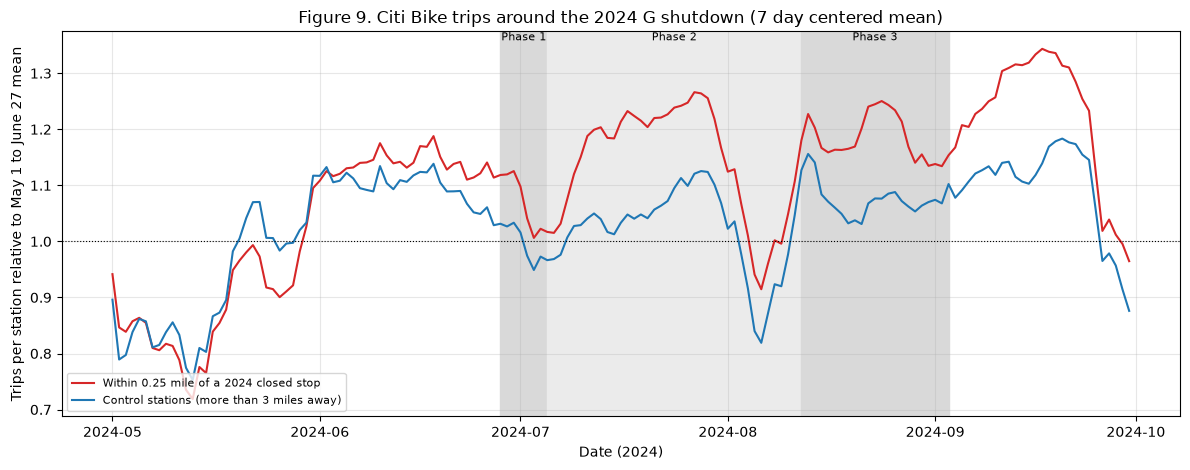

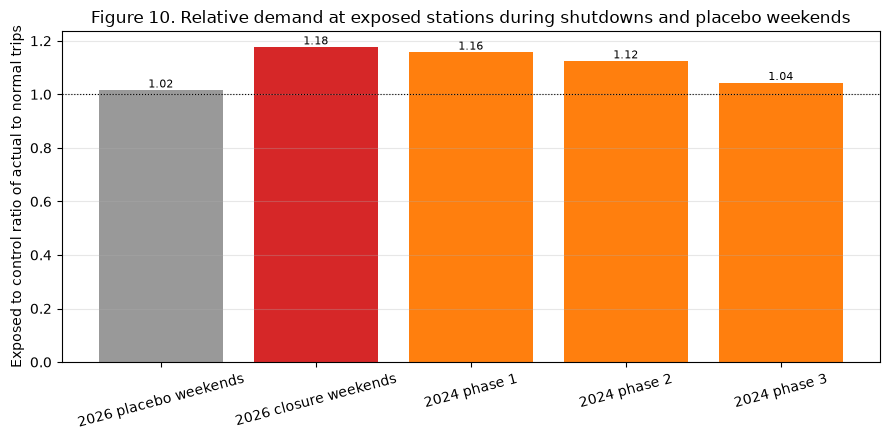

group,Control stations,Exposed stations,exposed_to_control
event,,,
2026 placebo weekends,0.976,0.991,1.016
2026 closure weekends,1.103,1.298,1.177
2024 phase 1,1.006,1.164,1.157
2024 phase 2,1.008,1.133,1.124
2024 phase 3,1.060,1.106,1.044


In [21]:
import matplotlib.pyplot as plt

# Figure 9: 2024 shutdown check. Daily trips per station relative to the pre shutdown mean, exposed versus control.
p24 = panel_extended[panel_extended["period"].eq("2024") & panel_extended["station_active"]].copy()
p24["group"] = np.where(p24["exposed_station_2024"], "Within 0.25 mile of a 2024 closed stop",
                        np.where(p24["station_group"].eq("control"), "Control stations (more than 3 miles away)", "Other corridor stations"))
p24 = p24[~p24["group"].eq("Other corridor stations")]
daily = p24.groupby(["group", p24["hour"].dt.normalize()])["total_trips"].sum().rename("trips").reset_index()
stations_per_group = p24.groupby("group")["short_name"].nunique()
daily["per_station"] = daily["trips"] / daily["group"].map(stations_per_group)
pre_mean = daily[daily["hour"] < "2024-06-28"].groupby("group")["per_station"].mean()
daily["index"] = daily["per_station"] / daily["group"].map(pre_mean)
daily["smooth"] = daily.groupby("group")["index"].transform(lambda values: values.rolling(7, center=True, min_periods=4).mean())
fig, axis = plt.subplots(figsize=(12, 4.8))
for label, color in (("Within 0.25 mile of a 2024 closed stop", "tab:red"), ("Control stations (more than 3 miles away)", "tab:blue")):
    part = daily[daily["group"].eq(label)]
    axis.plot(part["hour"], part["smooth"], color=color, label=label)
for label, start, end, shade in (("Phase 1", "2024-06-28", "2024-07-05", "0.85"), ("Phase 2", "2024-07-05", "2024-08-12", "0.92"), ("Phase 3", "2024-08-12", "2024-09-03", "0.85")):
    axis.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=shade, zorder=0)
    axis.text(pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2, axis.get_ylim()[1], label, ha="center", va="top", fontsize=8)
axis.axhline(1, color="black", linewidth=0.8, linestyle=":")
axis.set_xlabel("Date (2024)")
axis.set_ylabel("Trips per station relative to May 1 to June 27 mean")
axis.set_title("Figure 9. Citi Bike trips around the 2024 G shutdown (7 day centered mean)")
axis.legend(fontsize=8, loc="lower left")
axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Figure 10: actual to normal profile ratio at exposed versus control stations, by event type
def ratio_table(frame, label):
    rows = []
    for group_name, mask in (("Exposed stations", frame["event_exposed_or_segment"]), ("Control stations", frame["station_group"].eq("control"))):
        part = frame[mask & frame["profile_total_trips"].gt(0)]
        rows.append({"event": label, "group": group_name, "station_hours": len(part),
                     "actual_to_profile": part["total_trips"].sum() / part["profile_total_trips"].sum()})
    return rows
effect_frame = panel_extended[panel_extended["profile_total_trips"].notna() & panel_extended["station_active"]].copy()
effect_frame["event_exposed_or_segment"] = np.where(effect_frame["g_closure_hour"], effect_frame["event_exposed"], effect_frame["exposed_station"])
effect_rows = []
effect_rows += ratio_table(effect_frame[effect_frame["event_type"].eq("2026 weekend closure")], "2026 closure weekends")
effect_rows += ratio_table(effect_frame[effect_frame["placebo_weekend_hour"]], "2026 placebo weekends")
for phase in ("2024 phase 1", "2024 phase 2", "2024 phase 3"):
    effect_rows += ratio_table(effect_frame[effect_frame["event_type"].eq(phase)], phase)
event_effect_table = pd.DataFrame(effect_rows)
wide = event_effect_table.pivot(index="event", columns="group", values="actual_to_profile")
wide["exposed_to_control"] = wide["Exposed stations"] / wide["Control stations"]
order = ["2026 placebo weekends", "2026 closure weekends", "2024 phase 1", "2024 phase 2", "2024 phase 3"]
wide = wide.loc[order]
fig, axis = plt.subplots(figsize=(9, 4.5))
bars = axis.bar(wide.index, wide["exposed_to_control"], color=["0.6", "tab:red", "tab:orange", "tab:orange", "tab:orange"])
axis.axhline(1, color="black", linewidth=0.8, linestyle=":")
axis.bar_label(bars, fmt="%.2f", fontsize=8)
axis.set_ylabel("Exposed to control ratio of actual to normal trips")
axis.set_title("Figure 10. Relative demand at exposed stations during shutdowns and placebo weekends")
axis.tick_params(axis="x", labelrotation=15)
axis.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()
display(wide.round(3))
event_effect_table.to_csv(PROCESSED_DIR / "shutdown_effect_screening.csv", index=False)

**Figure 9 and Figure 10 explanation.** Figure 9 shows trips per station relative to the May 1 to June 27, 2024 mean, as a seven day centered average, for stations within 0.25 mile of a closed 2024 stop and for control stations. Both lines rise into summer, which is seasonal growth and not a shutdown effect. The line for exposed stations sits above the control line through the three shutdown phases (the shaded bands), which means demand near the closed stops grew faster than demand elsewhere.

Figure 10 turns that comparison into one number per event type: the ratio of actual trips to the normal profile at exposed stations divided by the same ratio at control stations. A value of 1 means no relative change. Placebo weekends give 1.01, so the method finds no effect when nothing happened. Confirmed 2026 closure weekends give 1.17. The three 2024 phases give 1.16, 1.12 and 1.04. The 2024 phase 2 value of about 12 percent is close to the nearly 14 percent increase reported in the proposal. These values are descriptive screening results: they support the main hypothesis that demand rises near closed stops, but they do not control for weather, hour of day or station size. The models in Section 4 will do that. Phase 1 and phase 3 have few exposed station hours (2,923 and 6,206), so they are less certain than phase 2 (39,547).

# 3. Exploration: exploratory data analysis and feature engineering

Exploratory analysis will describe the data before any predictive or causal model is fit. Tables and plots will include the sample size, time span, and aggregation level needed to interpret them. Every plot in this section is generated from the local data, states its sample and time span, and is followed by an interpretation.

## 3.1 Coverage, data quality, and study period

The data quality table in Section 2 reports source rows, excluded endpoint records, station identifiers that do not match the latest station file, and the overlap between trip and status hours. The local trip records used for the area figures cover May to September 2024 and January to September 2026 (hourly counts built in Section 2.6). Historical station status covers August 21 through October 1, 2026. Weather observations cover the same trip months, and the subway stop lookup provides coordinates for G train stops. MTA alert updates currently end on August 11, 2026, before the status sample, and the live alert snapshot only lists G work from October 19, 2026. Some rides in each trip archive start or end just outside the month in its file name, so the timestamp of each measured event defines the analysis period. Closure intervals are taken from MTA planned service notices for 13 weekends in 2026 (Section 2.2.1) and from the 2024 shutdown phases (Section 2.6). Only the three weekends from August 21 onward overlap station status.

Trip records from August 21 to September 30, 2026 overlap with station status in time. Trips in the other months do not have matching historical station status in the local files, and status continues beyond the trip period. The two sources are therefore analyzed separately except where station and hour keys match. This prevents a missing record in one source from being interpreted as a measured zero in another.

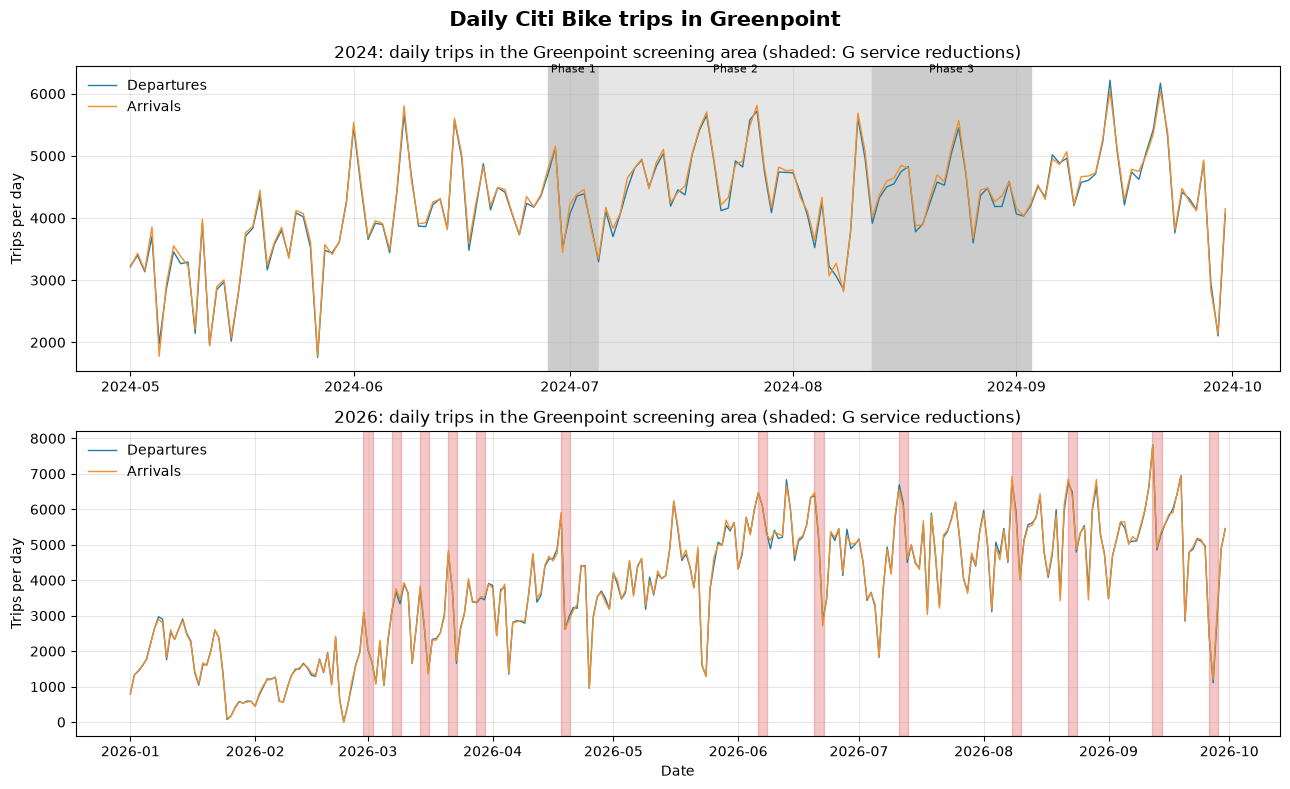

,departures,arrivals,calendar days,mean departures per day,mean arrivals per day
2024-05,100989,102035,31,3257.7,3291.5
2024-06,129800,130818,30,4326.7,4360.6
2024-07,142068,143659,31,4582.8,4634.2
2024-08,132960,134814,31,4289.0,4348.8
2024-09,136802,137216,30,4560.1,4573.9
2026-01,51589,51478,31,1664.2,1660.6
2026-02,35531,35696,28,1269.0,1274.9
2026-03,87991,88533,31,2838.4,2855.9
2026-04,104813,104741,30,3493.8,3491.4
2026-05,132106,133062,31,4261.5,4292.3


In [22]:
import matplotlib.pyplot as plt

# Area totals for the 43 Greenpoint stations over all extended trip months (2024 and 2026)
area_codes = set(greenpoint_stations["trip_station_id"].dropna())
area_hourly_all = (
    trip_hourly[trip_hourly["short_name"].isin(area_codes)]
    .groupby("hour")[["departures", "arrivals"]].sum()
)
MONTHS_FOR_EXPLORATION = tuple(
    [f"2024-{month:02d}" for month in range(5, 10)] + [f"2026-{month:02d}" for month in range(1, 10)]
)
monthly_hourly = {}
monthly_daily = {}
for month in MONTHS_FOR_EXPLORATION:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthBegin(1)
    hour_index = pd.date_range(month_start, month_end, freq="h", inclusive="left")
    hourly = area_hourly_all.reindex(hour_index, fill_value=0)
    monthly_hourly[month] = hourly
    monthly_daily[month] = hourly.resample("D").sum()

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for axis, year in zip(axes, ("2024", "2026")):
    daily = pd.concat([monthly_daily[m] for m in MONTHS_FOR_EXPLORATION if m.startswith(year)])
    axis.plot(daily.index, daily["departures"], label="Departures", color="#247ba0", linewidth=1)
    axis.plot(daily.index, daily["arrivals"], label="Arrivals", color="#f28e2b", linewidth=1)
    if year == "2024":
        for label, start, end, shade in (("Phase 1", "2024-06-28", "2024-07-05", "0.8"),
                                         ("Phase 2", "2024-07-05", "2024-08-12", "0.9"),
                                         ("Phase 3", "2024-08-12", "2024-09-03", "0.8")):
            axis.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=shade, zorder=0)
            axis.text(pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2,
                      daily[["departures", "arrivals"]].max().max() * 1.02, label, ha="center", fontsize=8)
    else:
        for window in pd.concat([g_confirmed_pre_august[["start_local", "end_local"]],
                                 g_confirmed_windows[["start_local", "end_local"]]]).itertuples():
            axis.axvspan(window.start_local, window.end_local, color="tab:red", alpha=0.25, zorder=0)
    axis.set_title(f"{year}: daily trips in the Greenpoint screening area (shaded: G service reductions)")
    axis.set_ylabel("Trips per day")
    axis.grid(alpha=0.3)
    axis.legend(frameon=False, loc="upper left")
axes[-1].set_xlabel("Date")
fig.suptitle("Daily Citi Bike trips in Greenpoint", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

daily_totals = pd.DataFrame(
    {month: monthly_daily[month][["departures", "arrivals"]].sum() for month in MONTHS_FOR_EXPLORATION}
).T
daily_totals["calendar days"] = [len(monthly_daily[month]) for month in MONTHS_FOR_EXPLORATION]
daily_totals["mean departures per day"] = daily_totals["departures"] / daily_totals["calendar days"]
daily_totals["mean arrivals per day"] = daily_totals["arrivals"] / daily_totals["calendar days"]
display(daily_totals.round(1))

**Figure 1. Daily Citi Bike departures and arrivals in the Greenpoint screening area, May to September 2024 and January to September 2026.** The top panel shows 2024 and the bottom panel shows 2026, with counts assigned by the recorded trip start and end times. Gray bands in the top panel mark the three phases of the 2024 G shutdown. Red bands in the bottom panel mark the 13 confirmed 2026 weekend closures. The months between October 2024 and December 2025 are not part of the study data, so they are not shown.

**Interpretation.** Demand follows a strong seasonal cycle. Mean departures per day rise from 1,269 in February 2026, the lowest month, to 5,268 in August 2026, the highest. Within 2024, mean daily departures grew from 3,258 in May to 4,583 in July and stayed near 4,300 to 4,600 through September. Arrivals track departures closely in every month (the two lines almost overlap), which is expected for a set of stations where bikes that leave are returned nearby, so the net flow of the area is small. The same months are higher in 2026 than in 2024 (June 5,253 against 4,327 departures per day, and September 5,035 against 4,560), which is consistent with system growth, with more stations (40 active in 2024, 43 in August and September 2026) and with different weather. The repeated waves are the weekly cycle of weekdays and weekends. The closure bands run from Friday night to Monday morning, so they sit on the weekend part of that cycle, and no lasting change in the level of the series is visible after them. Several days in late January 2026 have close to zero trips, and 2026 has a clear dip at the end of September. The causes were not investigated here, and such days will matter for the weather controls in later models. Area totals hide differences between stations, so these plots cannot show whether stations near a closed stop behaved differently. That comparison is made at the station level in Section 2.6 and in Section 3.6. The station count also changes between months (for example 36 active stations in July 2026), so month to month comparisons mix demand changes with availability of stations.

## 3.2 Daily and hourly demand patterns

Figure 1 summarizes daily departures and arrivals in the Greenpoint screening area. Figure 2 compares average area wide activity by local hour and day type. Each month is shown separately because seasonal conditions differ. These are descriptive summaries across selected stations, not individual rider behavior.

The daily figure above shows total volume by date. The next figure examines how this activity is distributed across the hours of a typical weekday and weekend day.

## 3.3 Hourly demand profiles

Hourly profiles use the complete calendar grid for each of the 14 months, with unobserved station hour counts represented as zero only inside the local area wide trip totals. The next subsection examines spatial differences and the separate station inventory records.

**Figure 2. Average hourly trips by day type.** The left panel shows weekdays and the right panel shows weekends. Each line is one month from May to September 2024 (dashed) and January to September 2026 (solid), colored from the earliest to the latest month. The lines show mean total departures plus arrivals per clock hour across the Greenpoint screening area. Hours without a recorded area wide trip are included as zero within each calendar month.

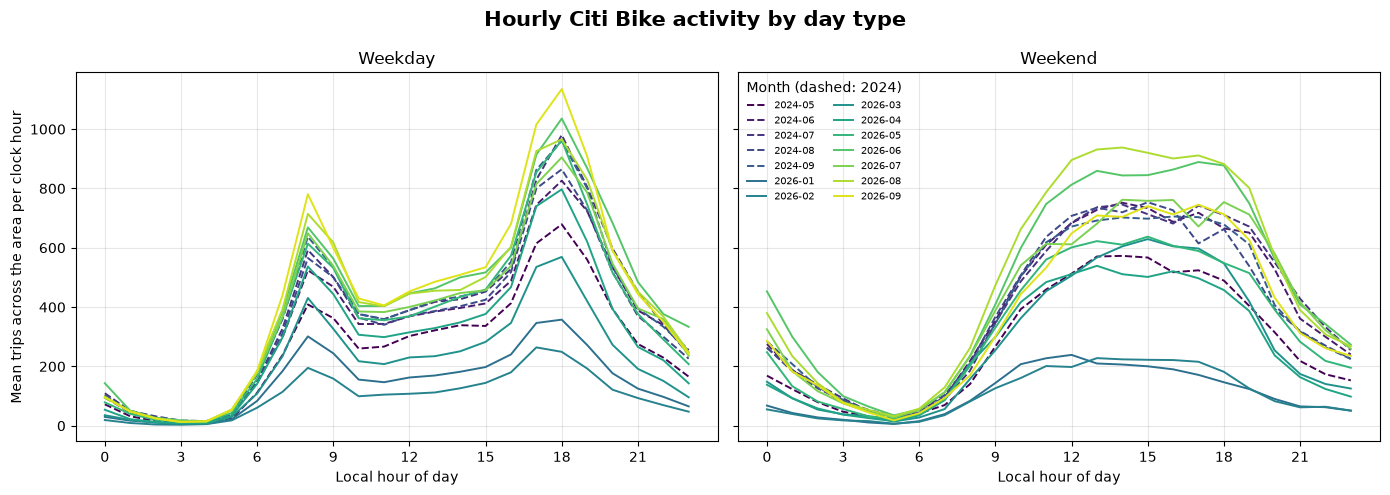

peak local hour         mean trips at peak        
day type         Weekday Weekend            Weekday Weekend
month                                                      
2024-05             18.0    14.0              679.0   572.6
2024-06             18.0    14.0              826.2   751.8
2024-07             18.0    14.0              980.2   745.8
2024-08             18.0    15.0              864.5   753.4
2024-09             18.0    16.0              961.2   705.4
2026-01             18.0    12.0              357.6   238.8
2026-02             17.0    13.0              264.1   227.9
2026-03             18.0    15.0              569.1   629.2
2026-04             18.0    13.0              797.0   539.1
2026-05             18.0    15.0              962.4   637.4
2026-06             18.0    17.0             1035.7   889.1
2026-07             18.0    14.0              904.8   762.0
2026-08             18.0    14.0              965.8   938.0
2026-09             18.0    17.0             1134.9   745.0

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
hourly_profiles = {}
peak_rows = []
colors = dict(zip(MONTHS_FOR_EXPLORATION, plt.cm.viridis(np.linspace(0, 0.95, len(MONTHS_FOR_EXPLORATION)))))

for month in MONTHS_FOR_EXPLORATION:
    hourly = monthly_hourly[month].copy()
    hourly["day_type"] = hourly.index.dayofweek.map(lambda day: "Weekend" if day >= 5 else "Weekday")
    hourly["hour_of_day"] = hourly.index.hour
    hourly["trips"] = hourly["departures"] + hourly["arrivals"]
    profile = hourly.groupby(["day_type", "hour_of_day"], observed=True)["trips"].mean().unstack("day_type")
    hourly_profiles[month] = profile
    for axis, day_type in zip(axes, ("Weekday", "Weekend")):
        axis.plot(profile.index, profile[day_type], color=colors[month], linewidth=1.4,
                  linestyle="--" if month.startswith("2024") else "-", label=month)
        peak_hour = profile[day_type].idxmax()
        peak_rows.append({"month": month, "day type": day_type, "peak local hour": int(peak_hour),
                          "mean trips at peak": round(float(profile.loc[peak_hour, day_type]), 1)})
for axis, day_type in zip(axes, ("Weekday", "Weekend")):
    axis.set_title(day_type)
    axis.set_xlabel("Local hour of day")
    axis.set_xticks(range(0, 24, 3))
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Mean trips across the area per clock hour")
axes[1].legend(frameon=False, fontsize=7, ncol=2, title="Month (dashed: 2024)", loc="upper left")
fig.suptitle("Hourly Citi Bike activity by day type", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

display(pd.DataFrame(peak_rows).pivot(index="month", columns="day type", values=["peak local hour", "mean trips at peak"]))

**Figure 2 interpretation.** The weekday profile has the same shape in every month: demand is low overnight, rises through the morning, and reaches its daily peak at 18:00 in 13 of the 14 months (17:00 in February 2026). The mean combined trips at the weekday peak range from 264 in February 2026 to 1,135 in September 2026. A morning peak at 08:00 is also clear and reaches roughly 60 to 70 percent of the evening peak, which is the commuter pattern of a residential area. The weekend profile has a single broad midday and afternoon hump, with its peak between 12:00 and 17:00, and in summer months more trips after midnight, with a peak of 239 in January 2026 and 938 in August 2026. The dashed 2024 lines have the same weekday shape as the 2026 lines, so the daily rhythm is stable across years and the 2024 data can be used as an external check of the shutdown effect. The curves rise from winter to late summer, which is the seasonal pattern also seen in Figure 1. These area summaries show when trip activity was highest in this sample, not why it was high. The hourly means include hours with no area trips. They do not control for weather or for the number of active stations, and the table of peak hours and peak means by month is the numeric form of the figure.

## 3.4 Spatial demand, station availability, and disruption limits

Station identifiers are matched to the latest station information snapshot, and station by hour keys are checked before plotting. Figure 3 ranks Greenpoint stations by total departures plus arrivals from January to September 2026 and checks whether the ranking held in summer 2024. Figure 4 measures the share of observed status snapshots with no open docks. A station with no bikes is a separate condition from one with no open docks. Station status exists only for August 21 to September 30, 2026, so Figure 4 cannot be extended to earlier months. The confirmed closure windows are linked to Citi Bike stations with a quarter mile distance rule in Sections 3.5 and 3.6, where the disruption comparison is made. That comparison is descriptive and is not a causal estimate.

**Figure 3. Station volume and stability across years.** The left panel ranks the ten busiest Greenpoint stations by departures plus arrivals from January to September 2026, with departures and arrivals stacked. The right panel compares the mean daily trips of the same stations in June to September 2024 and 2026.

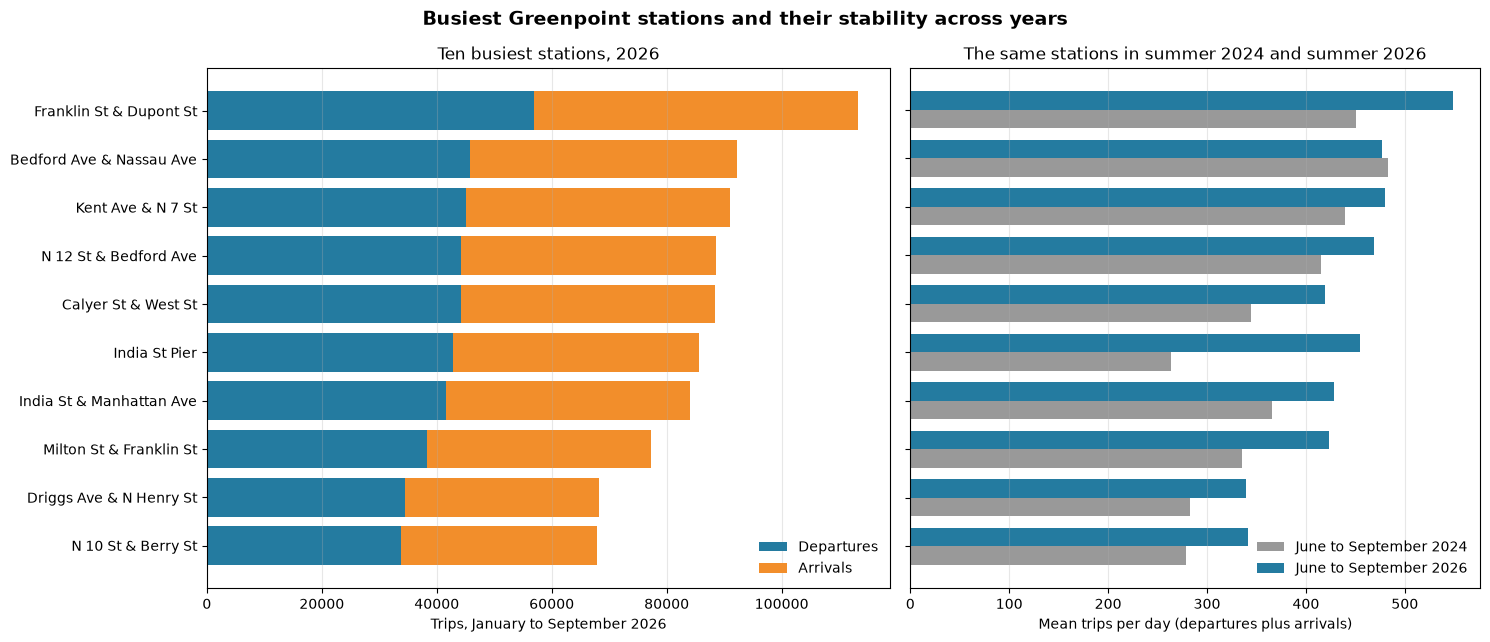

,departures,arrivals,total trips,share of area trips,"mean daily trips, summer 2024","mean daily trips, summer 2026"
name,,,,,,
Franklin St & Dupont St,56872,56397,113269,0.055,450.426,548.582
Bedford Ave & Nassau Ave,45847,46472,92319,0.045,482.697,476.730
Kent Ave & N 7 St,45095,45845,90940,0.044,439.254,479.893
N 12 St & Bedford Ave,44157,44382,88539,0.043,415.320,468.459
Calyer St & West St,44166,44242,88408,0.043,344.590,419.156
India St Pier,42772,42928,85700,0.042,263.107,454.451
India St & Manhattan Ave,41672,42299,83971,0.041,365.861,428.656
Milton St & Franklin St,38379,38859,77238,0.038,335.434,423.648
Driggs Ave & N Henry St,34495,33751,68246,0.033,283.197,339.484


Rank correlation of station volume, summer 2024 and summer 2026 (40 stations active in both): 0.894
Top ten stations in 2026 that were also in the top ten in summer 2024: 7 of 10
Share of all area trips at the ten busiest stations: 41.6%


In [24]:
# Station ranking over all 2026 months, and the stability of the busiest stations against summer 2024
name_by_code = greenpoint_stations.set_index("trip_station_id")["name"]
area_trips = trip_hourly[trip_hourly["short_name"].isin(name_by_code.index)].copy()
area_trips["name"] = area_trips["short_name"].map(name_by_code)
trips_2026 = area_trips[area_trips["hour"].between("2026-01-01", "2026-09-30 23:00")]
ranking_2026 = trips_2026.groupby("name")[["departures", "arrivals"]].sum()
ranking_2026["total trips"] = ranking_2026["departures"] + ranking_2026["arrivals"]
top_stations = ranking_2026.nlargest(10, "total trips").sort_values("total trips")

def summer_daily_mean(frame, start, end):
    window = frame[frame["hour"].between(start, end + " 23:00")]
    days = (pd.Timestamp(end) - pd.Timestamp(start)).days + 1
    return (window.groupby("name")[["departures", "arrivals"]].sum().sum(axis=1) / days)
summer_2024 = summer_daily_mean(area_trips, "2024-06-01", "2024-09-30").reindex(top_stations.index).fillna(0)
summer_2026 = summer_daily_mean(area_trips, "2026-06-01", "2026-09-30").reindex(top_stations.index).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})
positions = np.arange(len(top_stations))
axes[0].barh(positions, top_stations["departures"], label="Departures", color="#247ba0")
axes[0].barh(positions, top_stations["arrivals"], left=top_stations["departures"], label="Arrivals", color="#f28e2b")
axes[0].set_yticks(positions, top_stations.index)
axes[0].set_xlabel("Trips, January to September 2026")
axes[0].set_title("Ten busiest stations, 2026")
axes[0].legend(frameon=False)
height = 0.38
axes[1].barh(positions - height / 2, summer_2024, height, label="June to September 2024", color="0.6")
axes[1].barh(positions + height / 2, summer_2026, height, label="June to September 2026", color="#247ba0")
axes[1].set_yticks(positions, [""] * len(positions))
axes[1].set_xlabel("Mean trips per day (departures plus arrivals)")
axes[1].set_title("The same stations in summer 2024 and summer 2026")
axes[1].legend(frameon=False)
for axis in axes:
    axis.grid(alpha=0.3, axis="x")
fig.suptitle("Busiest Greenpoint stations and their stability across years", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

top_table = top_stations.sort_values("total trips", ascending=False).copy()
top_table["share of area trips"] = top_table["total trips"] / ranking_2026["total trips"].sum()
top_table["mean daily trips, summer 2024"] = summer_2024
top_table["mean daily trips, summer 2026"] = summer_2026
display(top_table.round(3))
rank_2024 = summer_daily_mean(area_trips, "2024-06-01", "2024-09-30")
rank_2026 = summer_daily_mean(area_trips, "2026-06-01", "2026-09-30")
common = rank_2024.index.intersection(rank_2026.index)
print(f"Rank correlation of station volume, summer 2024 and summer 2026 ({len(common)} stations active in both): "
      f"{rank_2024[common].rank().corr(rank_2026[common].rank()):.3f}")
print(f"Top ten stations in 2026 that were also in the top ten in summer 2024: "
      f"{len(set(top_stations.index) & set(rank_2024.nlargest(10).index))} of 10")
print(f"Share of all area trips at the ten busiest stations: {top_stations['total trips'].sum() / ranking_2026['total trips'].sum():.1%}")



**Figure 3 interpretation.** Franklin St & Dupont St is the busiest station with 113,269 trips (56,872 departures and 56,397 arrivals), followed by Bedford Ave & Nassau Ave with 92,319 and Kent Ave & N 7 St with 90,940. The ten stations carry 41.6 percent of all trips in the area, so demand is concentrated. Departures and arrivals are nearly equal at every station, which means these stations are not persistent sources or sinks over the full period. The right panel shows stability: the rank correlation of station volume between summer 2024 and summer 2026 is 0.894 across the 40 stations active in both, and seven of the ten leading stations were already in the top ten in 2024. Volume rose at most stations, most strongly at India St Pier (263 to 454 mean daily trips). The ranking therefore supports using station level baselines across both years, but it does not identify which stations were affected by a closure.

**Figure 4. Share of station status snapshots reporting no open docks.** The figure compares weekdays and weekends by local hour over the available station status period, August 21 through October 1, 2026. The denominator is the number of station status observations, not the number of stations.

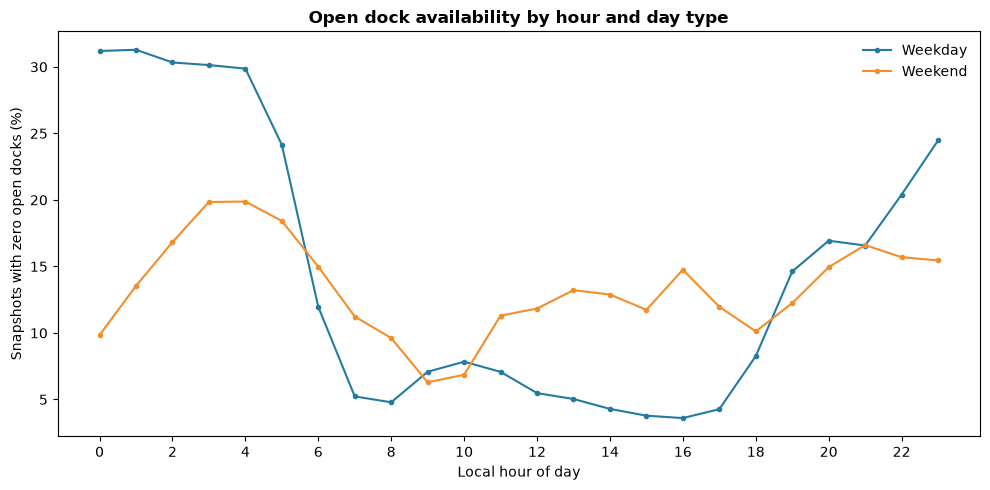

Overall snapshot shares by day type


,zero dock percent,zero bike percent,snapshots
day_type,,,
Weekday,14.56,1.64,357607.0
Weekend,13.34,0.71,148032.0


In [25]:
availability_profile = (
    greenpoint_status.groupby(["day_type", "hour_of_day"], observed=True)
    .agg(
        zero_dock_snapshots=("zero_dock_snapshots", "sum"),
        zero_bike_snapshots=("zero_bike_snapshots", "sum"),
        snapshots=("snapshot_count", "sum"),
    )
)
availability_profile["zero dock percent"] = (
    100 * availability_profile["zero_dock_snapshots"] / availability_profile["snapshots"]
)
availability_profile["zero bike percent"] = (
    100 * availability_profile["zero_bike_snapshots"] / availability_profile["snapshots"]
)

fig, axis = plt.subplots(figsize=(10, 5))
for day_type, color in (("Weekday", "#247ba0"), ("Weekend", "#f28e2b")):
    series = availability_profile.xs(day_type, level="day_type")["zero dock percent"]
    axis.plot(series.index, series, marker="o", markersize=3, label=day_type, color=color)
axis.set_xlabel("Local hour of day")
axis.set_ylabel("Snapshots with zero open docks (%)")
axis.set_xticks(range(0, 24, 2))
axis.set_title("Open dock availability by hour and day type", fontweight="bold")
axis.legend(frameon=False)
fig.tight_layout()
plt.show()

print("Overall snapshot shares by day type")
display(availability_profile.groupby(level="day_type").apply(
    lambda group: pd.Series({
        "zero dock percent": 100 * group["zero_dock_snapshots"].sum() / group["snapshots"].sum(),
        "zero bike percent": 100 * group["zero_bike_snapshots"].sum() / group["snapshots"].sum(),
        "snapshots": group["snapshots"].sum(),
    })
).round(2))

**Figure 4 interpretation.** Across the collected snapshots, zero open docks were reported in 14.56% of weekday observations and 13.34% of weekend observations. Zero bikes were less common, at 1.64% and 0.71%, respectively. This suggests that the observed inventory constraint was more often a lack of return capacity than a lack of bikes, within this station screen and period. These percentages describe snapshots, not every moment between feed updates, and they do not show that a subway closure caused the inventory pattern.

## 3.5 Feature engineering

The preparation cell creates calendar features from the local event time and joins current station attributes using station identifiers. Candidate features for later modeling include:

1. **Hour of day.** The local hour from the analysis timestamp represents daily travel patterns. Confirm local time and daylight saving handling.
2. **Day of week.** The local weekday separates weekday and weekend travel. Confirm category ordering and holidays.
3. **Weekend indicator.** Whether the date falls on Saturday or Sunday provides a simple day type summary. Compare with a full weekday category.
4. **Station attributes.** Location and capacity represent differences in station setting and size. Check dated capacity and identifier matches.
5. **Weather measures.** Temperature and precipitation from the historical archive may account for travel conditions. The station to grid lookup follows the supplied Citi Bike pipeline reference. Check units, local time, spatial resolution, coverage, and missingness before modeling.
6. **Service disruption indicator.** Whether a verified event affects a station and hour identifies event timing and exposure. Use actual service times, not notice publication time alone.
7. **Distance to affected stop.** Geographic distance allows effects to vary with proximity. State the distance method and test more than one threshold.
8. **Recent demand summaries.** Past station activity represents local demand history. Use only information available at prediction time and prevent future data leakage.

The calendar features created for exploration are local hour, weekday, weekday or weekend, date, and calendar month. They describe regular time patterns and support the figures above. Weather, closure flags (`g_closure_hour`, `exposed_closure_hour`), distance to the nearest affected stop, lags and the weekly baseline are joined in the panels of Sections 2.5 and 2.6. Any later model feature must be available at forecast time. Station status measures describe reported inventory, not trip counts.

## 3.6 Exposure map and the effect of confirmed G reductions

Figure 5 maps the exposure definition for the 94 corridor stations. Figure 6 then compares exposed, other corridor and control stations during 2026 weekend hours with and without a confirmed G reduction, using the 13 confirmed weekends, dry hours only and excluding holidays. The comparison uses only hours of the day that occur in a closure window, so that the groups cover the same clock hours. The outcome is the ratio of actual trips to each station's normal profile for the same weekday and hour. The comparison is descriptive: it does not adjust for events or station differences.

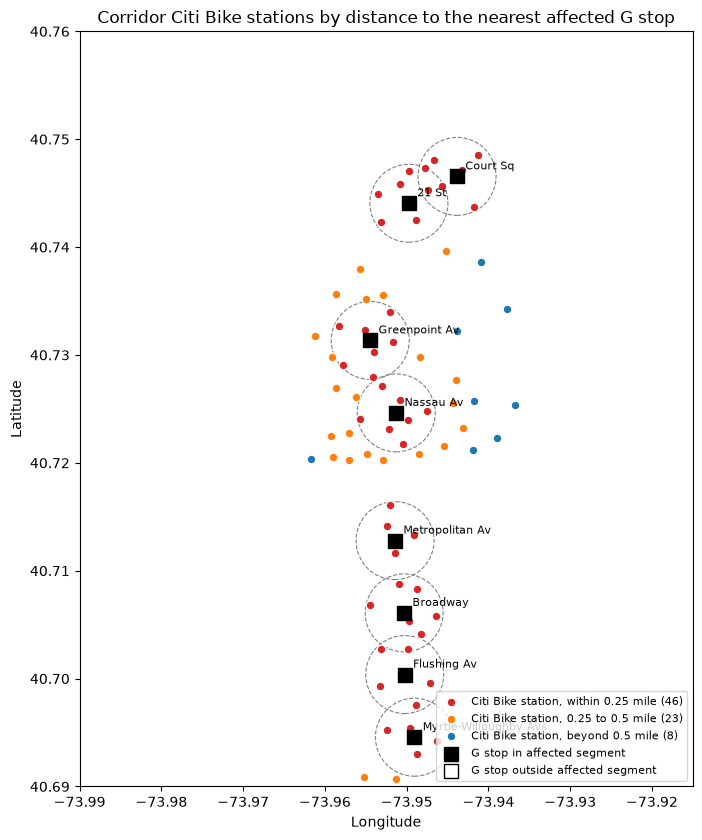

Corridor stations in the map window: 77 of 94
Within 0.25 mile of the affected segment: 46 (14 in the Greenpoint screen)


,stations,mean_capacity,median_miles
distance_band,,,
Within 0.25 mile,46,29.20,0.18
0.25 to 0.5 mile,24,34.46,0.37
Beyond 0.5 mile,24,31.21,0.91


In [26]:
from matplotlib.patches import Ellipse

# Distance from every model station (corridor group) to the nearest stop of the affected 2026 segment
segment_pairs = model_pairs[model_pairs["gtfs_stop_id"].isin(segment_stop_ids)]
map_stations = model_stations.merge(
    segment_pairs.groupby("short_name")["distance_miles"].min().rename("segment_miles"),
    on="short_name", how="left",
)
map_stations = map_stations[map_stations["station_group"].eq("corridor")].copy()
map_stations["distance_band"] = pd.cut(
    map_stations["segment_miles"], [0, 0.25, 0.5, np.inf],
    labels=["Within 0.25 mile", "0.25 to 0.5 mile", "Beyond 0.5 mile"], include_lowest=True,
)
map_stations["in_greenpoint_screen"] = map_stations["short_name"].isin(greenpoint_stations["short_name"])

fig, ax = plt.subplots(figsize=(8.5, 8.5))
band_colors = {"Within 0.25 mile": "tab:red", "0.25 to 0.5 mile": "tab:orange", "Beyond 0.5 mile": "tab:blue"}
view = dict(lat=(40.690, 40.760), lon=(-73.990, -73.915))
visible = map_stations[map_stations["lat"].between(*view["lat"]) & map_stations["lon"].between(*view["lon"])]
for band, color in band_colors.items():
    subset = visible[visible["distance_band"] == band]
    ax.scatter(subset["lon"], subset["lat"], s=40, color=color, edgecolor="white",
               label=f"Citi Bike station, {band.lower()} ({len(subset)})", zorder=3)

near_area = mta_g_stops[mta_g_stops["gtfs_latitude"].between(*view["lat"]) & mta_g_stops["gtfs_longitude"].between(*view["lon"])]
affected_near = near_area[near_area["affected_segment"]]
unaffected_near = near_area[~near_area["affected_segment"]]
ax.scatter(affected_near["gtfs_longitude"], affected_near["gtfs_latitude"], marker="s", s=90, color="black", label="G stop in affected segment", zorder=4)
ax.scatter(unaffected_near["gtfs_longitude"], unaffected_near["gtfs_latitude"], marker="s", s=90, facecolor="white", edgecolor="black", label="G stop outside affected segment", zorder=4)
for stop in affected_near.itertuples():
    ax.annotate(stop.stop_name, (stop.gtfs_longitude, stop.gtfs_latitude), textcoords="offset points", xytext=(6, 5), fontsize=8)
    radius_lat = 0.402336 / 111.32
    radius_lon = 0.402336 / (111.32 * np.cos(np.radians(stop.gtfs_latitude)))
    ax.add_patch(Ellipse((stop.gtfs_longitude, stop.gtfs_latitude), 2 * radius_lon, 2 * radius_lat, fill=False, linestyle="--", color="gray", linewidth=0.8))

ax.set_xlim(*view["lon"])
ax.set_ylim(*view["lat"])
ax.set_aspect(1 / np.cos(np.radians(40.725)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Corridor Citi Bike stations by distance to the nearest affected G stop")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

print(f"Corridor stations in the map window: {len(visible)} of {len(map_stations)}")
print(f"Within 0.25 mile of the affected segment: {int(map_stations['distance_band'].eq('Within 0.25 mile').sum())} "
      f"({int((map_stations['distance_band'].eq('Within 0.25 mile') & map_stations['in_greenpoint_screen']).sum())} in the Greenpoint screen)")
display(map_stations.groupby("distance_band", observed=True).agg(
    stations=("short_name", "size"), mean_capacity=("capacity", "mean"),
    median_miles=("segment_miles", "median")).round(2))


**Interpretation of Figure 5.** The map shows the 77 of the 94 corridor model stations that fall inside the plotted window, colored by distance to the nearest stop of the affected G segment (Court Sq to Bedford-Nostrand Avs), with quarter mile circles around each stop. In the plotted window, 46 stations lie within 0.25 mile (median 0.18 mile), 23 lie between 0.25 and 0.5 mile and 8 lie beyond 0.5 mile. Across all 94 corridor stations the counts are 46, 24 and 24. Of the 46 exposed stations, 14 are inside the Greenpoint screening rectangle, so the extended station set adds Long Island City and Williamsburg stations to the exposed group. Mean dock capacity is similar across bands (29.2, 34.5 and 31.2). The exposed group is spatially concentrated, so a difference between exposed and other stations may also reflect neighborhood density and land use. The map shows geometry only and says nothing about travel behavior.

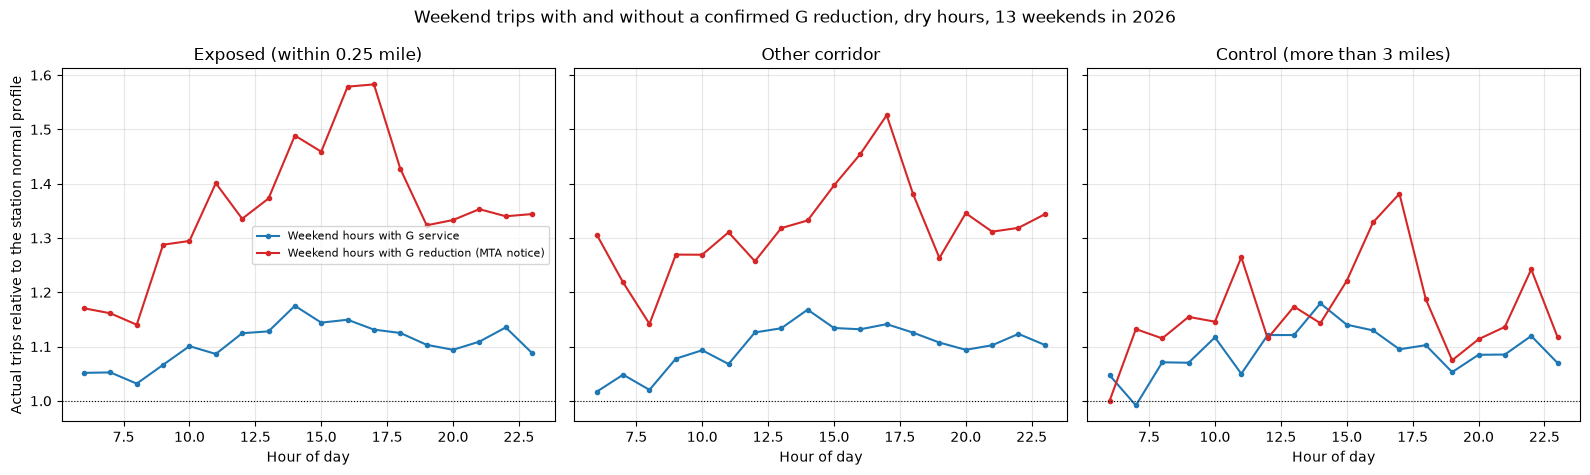

,actual to profile (service running),actual to profile (closure),station hours (service running),station hours (closure),closure to running ratio
group,,,,,
Control (more than 3 miles),1.100,1.184,35138.0,18187.0,1.077
Exposed (within 0.25 mile),1.115,1.393,31184.0,16078.0,1.249
Other corridor,1.113,1.337,31310.0,16168.0,1.202


Ratio of ratios, Exposed (within 0.25 mile) relative to control: 1.160
Ratio of ratios, Other corridor relative to control: 1.116
Closure weekends in the comparison: 24 days


In [27]:
# Weekend hours in 2026 with and without a confirmed G reduction, dry hours only, all model stations
weekend_all = panel_extended[
    panel_extended["period"].eq("2026") & panel_extended["station_active"] & panel_extended["is_weekend"] & ~panel_extended["is_holiday"]
    & panel_extended["hour_of_day"].between(6, 23) & ~panel_extended["precipitation_any"]
].copy()
closure_hour_set = sorted(weekend_all.loc[weekend_all["g_closure_hour"], "hour_of_day"].unique())
comparison = weekend_all[weekend_all["hour_of_day"].isin(closure_hour_set)].copy()
comparison["group"] = np.select(
    [comparison["exposed_station"], comparison["station_group"].eq("corridor")],
    ["Exposed (within 0.25 mile)", "Other corridor"], default="Control (more than 3 miles)",
)
# Ratio of actual trips to each station's normal profile for the same weekday and hour, summed over stations so large stations weigh more
comparison = comparison[comparison["profile_total_trips"].notna()]
def relative_level(frame):
    return frame["total_trips"].sum() / frame["profile_total_trips"].sum()
profile = (
    comparison.groupby(["group", "g_closure_hour", "hour_of_day"]).apply(relative_level, include_groups=False)
    .rename("relative_trips").reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
styles = [(False, "Weekend hours with G service", "tab:blue"), (True, "Weekend hours with G reduction (MTA notice)", "tab:red")]
for axis, group in zip(axes, ["Exposed (within 0.25 mile)", "Other corridor", "Control (more than 3 miles)"]):
    for closure_flag, label, color in styles:
        subset = profile[(profile["group"] == group) & (profile["g_closure_hour"] == closure_flag)]
        axis.plot(subset["hour_of_day"], subset["relative_trips"], marker="o", markersize=3, color=color, label=label)
    axis.axhline(1, color="black", linewidth=0.8, linestyle=":")
    axis.set_title(group)
    axis.set_xlabel("Hour of day")
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Actual trips relative to the station normal profile")
axes[0].legend(fontsize=8)
fig.suptitle("Weekend trips with and without a confirmed G reduction, dry hours, 13 weekends in 2026")
fig.tight_layout()
plt.show()

closure_summary = (
    comparison.groupby(["group", "g_closure_hour"]).apply(
        lambda frame: pd.Series({"actual to profile": relative_level(frame), "station hours": len(frame)}), include_groups=False)
    .unstack("g_closure_hour")
)
closure_summary.columns = [f"{stat} ({'closure' if flag else 'service running'})" for stat, flag in closure_summary.columns]
closure_summary["closure to running ratio"] = closure_summary["actual to profile (closure)"] / closure_summary["actual to profile (service running)"]
display(closure_summary.round(3))
ratio_control = closure_summary.loc["Control (more than 3 miles)", "closure to running ratio"]
for group in ("Exposed (within 0.25 mile)", "Other corridor"):
    print(f"Ratio of ratios, {group} relative to control: {closure_summary.loc[group, 'closure to running ratio'] / ratio_control:.3f}")
print(f"Closure weekends in the comparison: {comparison.loc[comparison['g_closure_hour'], 'hour'].dt.normalize().nunique()} days")




**Interpretation of Figure 6.** The figure shows actual trips relative to each station's normal profile, by hour of day, for weekend hours with and without a confirmed G reduction. Values above 1 mean more trips than the profile. Control stations more than 3 miles from the corridor move from 1.100 to 1.184 (ratio 1.077), which captures the general lift of closure weekends, for example from season and weather. Exposed stations within 0.25 mile move from 1.115 to 1.393 (ratio 1.249), and other corridor stations from 1.113 to 1.337 (ratio 1.202). Relative to control, the ratio of ratios is 1.160 for exposed stations and 1.116 for other corridor stations, so demand rose about 16 percent more near the closed segment than at control stations and the lift fades with distance. The comparison covers 24 closure days and uses dry hours only, so weather is held roughly constant. This agrees with the screening results in Section 2.6 (1.17 for 2026 weekends). It is a descriptive difference, not a causal estimate, because events and other weekend effects are not controlled. It motivates a count model with station, hour and weather controls.

## 3.7 Weather and the distribution of the outcome

Figure 7 relates weather to demand. Because demand depends strongly on the time of day, departures are expressed relative to the average for the same station, hour of day and day type before they are grouped by weather class. Figure 8 examines the distribution of hourly departures, because the choice of count model in the next stage depends on whether the variance is close to the mean.


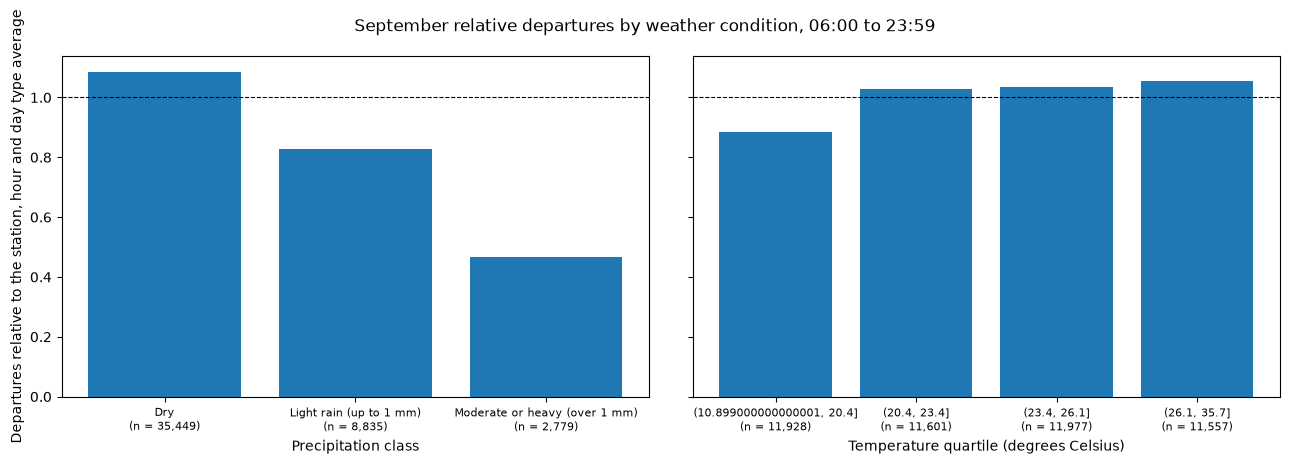

,mean,count
precipitation_class,,
Dry,1.084,35449
Light rain (up to 1 mm),0.829,8835
Moderate or heavy (over 1 mm),0.467,2779


Hours with any precipitation (all panel hours): 339


In [28]:
active = panel[panel["trip_observed"] & panel["hour_of_day"].between(6, 23)].copy()
expected_demand = active.groupby(["station_id", "hour_of_day", "is_weekend"])["departures"].transform("mean")
active["relative_departures"] = active["departures"] / expected_demand.replace(0, np.nan)
active["precipitation_class"] = np.select(
    [active["precipitation"].eq(0), active["precipitation"].le(1)],
    ["Dry", "Light rain (up to 1 mm)"],
    default="Moderate or heavy (over 1 mm)",
)
active["temperature_quartile"] = pd.qcut(active["temperature_2m"], 4)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for axis, column, order in (
    (axes[0], "precipitation_class", ["Dry", "Light rain (up to 1 mm)", "Moderate or heavy (over 1 mm)"]),
    (axes[1], "temperature_quartile", None),
):
    summary = active.groupby(column, observed=True)["relative_departures"].agg(["mean", "count"])
    if order:
        summary = summary.reindex(order)
    axis.bar(range(len(summary)), summary["mean"], color="tab:blue")
    axis.set_xticks(range(len(summary)))
    axis.set_xticklabels([f"{str(label)}\n(n = {int(n):,})" for label, n in zip(summary.index, summary["count"])], fontsize=8)
    axis.axhline(1, color="black", linewidth=0.8, linestyle="--")
    axis.set_xlabel("Precipitation class" if column == "precipitation_class" else "Temperature quartile (degrees Celsius)")
axes[0].set_ylabel("Departures relative to the station, hour and day type average")
fig.suptitle("September relative departures by weather condition, 06:00 to 23:59")
fig.tight_layout()
plt.show()

weather_summary = active.groupby("precipitation_class")["relative_departures"].agg(["mean", "count"]).round(3)
display(weather_summary)
print(f"Hours with any precipitation (all panel hours): {int((panel.drop_duplicates("hour")["precipitation"] > 0).sum())}")


**Interpretation of Figure 7.** Departures are scaled by the station, hour and day type average, so a value of 1 means typical demand. Dry hours average 1.08, light rain hours 0.83 and moderate or heavy rain hours 0.47. Demand falls steadily as precipitation rises, and the moderate or heavy class has far fewer observations (2,779) than the dry class (35,449). The rain effect is larger than the closure difference in Figure 6, so precipitation has to be kept as a control in any model, otherwise a rainy closure weekend could be mistaken for a closure effect. The weather grid is coarse relative to station locations, and the pattern is descriptive.

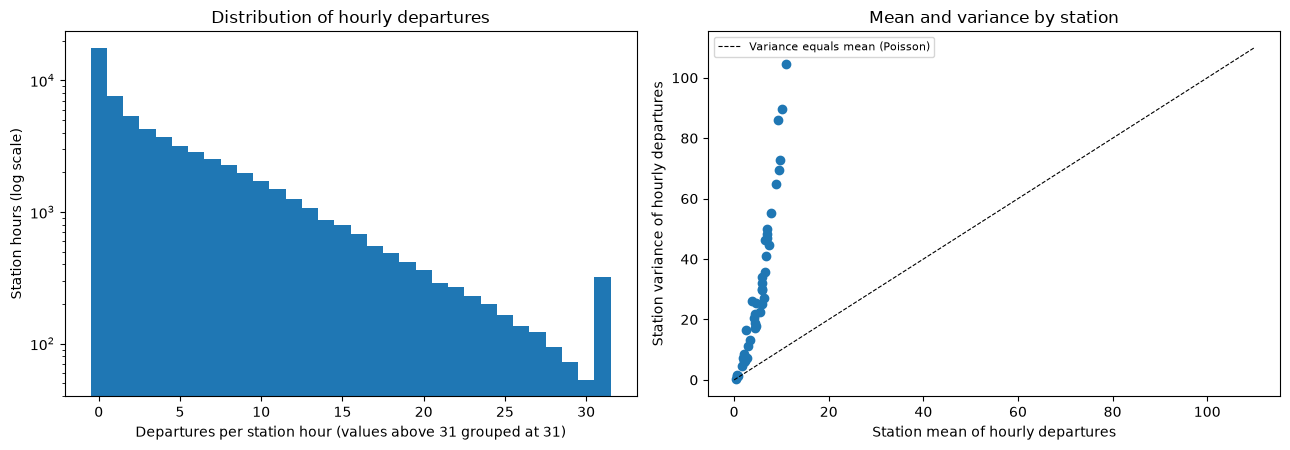

Mean departures per station hour: 4.994
Variance of departures per station hour: 38.084
Variance to mean ratio: 7.63
Share of station hours with zero departures: 28.0%
Median station level variance to mean ratio: 4.96


In [29]:
observed = panel[panel["trip_observed"]]
departures_mean = observed["departures"].mean()
departures_var = observed["departures"].var()
zero_share = observed["departures"].eq(0).mean()
station_moments = observed.groupby("station_id")["departures"].agg(["mean", "var"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
upper = int(observed["departures"].quantile(0.995))
axes[0].hist(observed["departures"].clip(upper=upper), bins=np.arange(0, upper + 2) - 0.5, color="tab:blue")
axes[0].set_yscale("log")
axes[0].set_xlabel(f"Departures per station hour (values above {upper} grouped at {upper})")
axes[0].set_ylabel("Station hours (log scale)")
axes[0].set_title("Distribution of hourly departures")
limit = float(station_moments[["mean", "var"]].max().max()) * 1.05
axes[1].scatter(station_moments["mean"], station_moments["var"], color="tab:blue")
axes[1].plot([0, limit], [0, limit], color="black", linestyle="--", linewidth=0.8, label="Variance equals mean (Poisson)")
axes[1].set_xlabel("Station mean of hourly departures")
axes[1].set_ylabel("Station variance of hourly departures")
axes[1].set_title("Mean and variance by station")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Mean departures per station hour: {departures_mean:.3f}")
print(f"Variance of departures per station hour: {departures_var:.3f}")
print(f"Variance to mean ratio: {departures_var / departures_mean:.2f}")
print(f"Share of station hours with zero departures: {zero_share:.1%}")
print(f"Median station level variance to mean ratio: {(station_moments['var'] / station_moments['mean']).median():.2f}")


**Interpretation of Figure 8.** The left panel shows the distribution of departures per station hour and the right panel the relation between the mean and the variance by station. Station hours average 4.99 departures with a variance of 38.08, a variance to mean ratio of 7.63, and 28.0 percent of station hours have zero departures. The median station level ratio is 4.96. A Poisson count has a ratio of 1, so the outcome is strongly overdispersed with excess zeros. This points toward a negative binomial or zero inflated count model, or a Poisson model with robust errors, rather than ordinary least squares on raw counts. Part of the overdispersion comes from the daily cycle and differences between stations, which later features will absorb, so the ratio is an upper bound on the dispersion that remains after modeling.

## 3.8 Dataset readiness for modeling

This section is the hand off to the modeling sections. It lists every ready table, says which one to start from, and gives the rules to follow before fitting anything. All ready tables are generated by this notebook from the raw files and are stored in `datasource/processed`, separate from the raw downloads and caches in `datasource`. They are saved as parquet (typed, compact, fast to read) or as small CSV files. Running the notebook again rebuilds them without downloading anything that already exists.

### Where to start

For almost all modeling work, load one table: the extended panel. The other tables are lookups or summaries that explain how it was built.

```python
import pandas as pd

panel = pd.read_parquet("datasource/processed/analysis_station_hour_panel_extended.parquet")
panel = panel[panel["station_active"]]                      # drop hours before a station opened or after it closed
train = panel[panel["split"] == "train"]                    # January to June 2026
valid = panel[panel["split"] == "validation"]               # July 2026
test = panel[panel["split"] == "test"]                      # August and September 2026
check_2024 = panel[panel["split"] == "validation_2024"]     # May to September 2024, external check
```

### Catalog of ready tables

| Table | Rows | Grain | Use it for |
|---|---|---|---|
| `analysis_station_hour_panel_extended.parquet` | 1,485,072 | station by clock hour, 153 stations | Main modeling table: outcomes, weather, calendar, shutdown flags, baseline, split. |
| `trip_hourly_model_stations.parquet` | 917,942 | station (`short_name`) by hour, only hours with trips | Intermediate hourly counts from the 58 million trip rows. Rebuild the panel from it; not needed for modeling. |
| `analysis_station_hour_panel.parquet` | 62,952 | station by hour, 43 Greenpoint stations, August and September 2026 | The Section 2.5 panel, the only one with Citi Bike status (bikes and docks available). |
| `mta_subway_shutdowns.csv` | 118 | one event by one affected G stop | Shutdown table from the proposal: event id, type, stop, start and end time, nearby stations. |
| `model_station_sets.csv` | 154 | station | Station lookup with `station_group` (94 corridor, 60 control) and distance to the nearest G stop. |
| `greenpoint_station_exposure.csv` | 43 | Greenpoint station | Distance to the nearest affected stop, `exposed_station` and `distance_band`. |
| `g_service_closures_confirmed.csv` | 4 | closure weekend | The August and September 2026 closure windows from MTA notices. |
| `g_service_closures_confirmed_pre_august.csv` | 9 | closure weekend | The nine earlier 2026 closure weekends (`times_assumed` marks inferred times). |
| `g_service_reduction_windows_inferred.csv` | 8 | window | Windows inferred from ridership, kept only as a cross check on the notices. |
| `baseline_accuracy_by_month.csv` | 24 | month by station group | Error of the four week baseline, the reference every model should beat. |
| `shutdown_effect_screening.csv` | 10 | event by group | Actual to profile demand ratio for each shutdown event, the descriptive effect behind Figure 6. |

`model_station_sets.csv` has 154 rows because it includes station `JC124`, which has no trips and so is absent from the panels (153 stations).

### Keys and how to join

- `station_id` (GBFS identifier) and `hour` (naive New York local time) identify one row of every panel. The pair is unique.
- Trip files use the short station code `short_name` (for example `4665.02`). Status files and the Section 2.5 panel use `station_id`. `model_station_sets.csv` maps one to the other. The extended panel carries both.
- `event_id` links the panel to `mta_subway_shutdowns.csv`. There are 16 events: three 2024 phases (E01 to E03) and thirteen 2026 closure weekends.

### Extended panel columns

| Group | Columns | Meaning |
|---|---|---|
| Keys and design | `station_id`, `short_name`, `hour`, `period`, `split`, `station_group` | `period` is 2024 or 2026. `split` is chronological: `train` 655,944 rows, `validation` 112,344, `test` 221,064, `validation_2024` 495,720. `station_group` is `corridor` (within reach of the affected G segment, 94 stations) or `control` (59 stations with trips). |
| Outcomes | `departures`, `arrivals`, `total_trips`, `net_flow` | Hourly counts. `net_flow` is arrivals minus departures. Zero is filled for hours without trips. |
| Weather | `temperature_2m`, `precipitation`, `precipitation_any` | Hourly values from one Open Meteo grid cell, the same for all stations. |
| Calendar | `hour_of_day`, `hour_sin`, `hour_cos`, `day_of_week`, `is_weekend`, `is_holiday` | The sine and cosine pair encodes the daily cycle. |
| Station attributes | `name`, `lat`, `lon`, `capacity`, `miles_to_nearest_g_stop` | From the latest station snapshot. |
| Shutdown flags | `g_closure_hour`, `exposed_closure_hour`, `event_id`, `event_type`, `event_exposed`, `distance_to_event_miles`, `exposed_station`, `exposed_station_2024`, `placebo_weekend_hour` | Whether the hour falls in a closure, whether the station is within a quarter mile of the affected stops, and the matching weekend hours with no closure used as placebo. |
| Reference demand | `baseline_departures`, `baseline_arrivals`, `baseline_total_trips`, `profile_departures`, `profile_arrivals`, `profile_total_trips` | `baseline_*` is the mean of the same hour in the previous four weeks, closure hours excluded, and needs at least two of them. `profile_*` is the mean per station, day of week and hour over a normal reference window. Both are expectations of normal demand, not outcomes. |
| Status | `bikes_available_mean`, `docks_available_mean`, `zero_bike_snapshots`, `zero_dock_snapshots`, `snapshot_count`, `status_observed`, `bikes_change`, `status_net_proxy`, `status_departure_proxy`, `status_arrival_proxy` | Filled only for the 43 Greenpoint stations after August 21, 2026 (about 3 percent of rows). `bikes_change` is the change in bikes available and the `status_*_proxy` columns are the demand proxies built from it. |
| Quality | `station_active` | False for 72,192 rows (4.9 percent) before a station's first trip or after its last. These zeros are not demand. |

The Section 2.5 panel keeps its own names for the same ideas (`zero_bike_share`, `zero_dock_share`, `departures_lag_24h`, `departures_lag_168h`, `nearest_affected_stop`, `nearest_affected_stop_miles`, `distance_band`, `trip_observed`). Use it when status data is the focus.

### Rules before modeling

1. Filter `station_active` to True before any fit or score. Figures 6, 9 and 10 and the baseline already do.
2. Never use `baseline_*`, `profile_*` or `status_*` columns as predictors of the same hour's outcome without checking leakage. The baseline uses only earlier weeks, but the profile uses the reference window and the status proxies are derived from the outcome.
3. Fit on `train`, tune on `validation`, report on `test`. Use `validation_2024` only to check that a shutdown effect also appears in a different year.
4. The baseline is missing for 253,793 of the 495,720 station hours in 2024 (the first four weeks of May, and hours whose earlier weeks fall in a closure or before a station opened). Check for missing values, or use the profile.
5. The outcome is a strongly overdispersed count (Figure 8), so start with a Poisson or negative binomial model and compare with the baseline errors in `baseline_accuracy_by_month.csv`.
6. Treat the shutdown effect results as descriptive. Corridor and control stations differ in demand level, so compare ratios to the profile, as in Figure 6, and not raw counts.

### Known limitations

- 13 of the 16 closure weekends proposed were found in MTA notices. Eight of the earlier weekends use assumed times, and the 2024 phase dates come from web notices and use whole days.
- Station status covers only Greenpoint from August 21 to September 30, 2026, and three of the four August and September closure weekends overlap it.
- One weather grid cell serves all stations, and weather on closure weekends was not matched to comparison weekends.
- Station attributes come from the latest snapshot. Exposure uses distance to a stop, not ridership by station.
- Skipped stop work on the southern F and G section is not treated as a closure.
- Trip loading reads four fields only, so there is no outlier removal and no duplicate ride id check. Daylight saving transitions are assumed ignorable.

## 3.9 Exploration summary

The local files support a descriptive baseline for 43 stations in the Greenpoint screening rectangle. September activity was higher than January, and the hourly profiles show different weekday and weekend peaks. Zero open docks were reported more often than zero bikes.

Four MTA Weekender notices (August 7 to 10, August 21 to 24, September 11 to 14 and September 25 to 28) confirm a G suspension between Court Sq and Bedford-Nostrand Avs. Hourly ridership agrees with the notices: all inferred reduction hours fall inside the confirmed windows. Eight G stops are affected, and 14 of 43 stations lie within a quarter mile of one. The analysis panel (62,952 station hour rows from August 1 to September 30) joins trips, status, weather, exposure and closure flags. Figure 6 uses the extended panel, the 13 confirmed 2026 weekends and dry hours, and gives a ratio of ratios of 1.16 for exposed stations and 1.12 for other corridor stations relative to control. Rain lowers relative demand strongly (0.47 for moderate or heavy rain against 1.08 dry). Departures are overdispersed (variance to mean ratio 7.6, 28 percent zeros).

Limits: 13 of the 16 closure weekends were found (eight use assumed times), status starts on August 21, one weather cell serves all stations, and weather on closure weekends was not matched to comparison weekends. These results are descriptive and do not establish a causal effect. Section 2.6 extends the data to 153 stations, 14 trip months and 16 shutdown events, adds a four week baseline and a normal profile, and gives a screening result: demand at exposed stations relative to control stations is 1.01 on placebo weekends, 1.17 on confirmed 2026 closure weekends and 1.12 in 2024 phase 2. Next steps are to fit count models with station, hour and weather controls on the chronological split.


# 4. Model development


## 4.1 Modeling design

The model is a counterfactual demand forecaster. It learns normal hourly demand at each station from hours when the G train was running. During a closure it predicts what demand would have been with normal service. The ratio of actual to predicted demand at exposed stations, compared with control stations, measures how demand shifts during a disruption.

Design choices:

1. **Unit and target.** One station in one hour. The first target is `departures`; `arrivals` follows the same pipeline.
2. **Training data.** The `train` split (January to June 2026), active stations only, with every closure hour removed. A counterfactual model must never see disrupted hours, or it learns the effect it is supposed to measure.
3. **Tuning and testing.** Tune on `validation` (July 2026). Report accuracy on normal hours in `test` (August and September 2026). Closure hours in `test` are scored separately to estimate the disruption effect.
4. **Reference.** Every model must beat the four week baseline (`baseline_departures`).
5. **Predictors.** Only information known at forecast time: calendar, weather, station attributes and station identity. The `baseline_*`, `profile_*` and `status_*` columns are not used as predictors.

In [30]:
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED_DIR = Path("datasource") / "processed"
panel = pd.read_parquet(PROCESSED_DIR / "analysis_station_hour_panel_extended.parquet")

# Rows before a station opened or after it closed are zeros, not demand
panel = panel[panel["station_active"]].copy()

# Closure hours: any hour inside a confirmed G closure window
closure = panel["g_closure_hour"].fillna(False).astype(bool)
panel["is_closure"] = closure

splits = ["train", "validation", "test", "validation_2024"]
summary = (
    panel.groupby(["split", "is_closure"])
    .size()
    .unstack(fill_value=0)
    .reindex(splits)
)
summary.columns = ["normal_hours", "closure_hours"]
print(summary)
print("\nStations:", panel["station_id"].nunique())
print("Station groups:\n", panel.drop_duplicates("station_id")["station_group"].value_counts())

                 normal_hours  closure_hours
split                                       
train                  549844          62095
validation              99697           7975
test                   182338          32230
validation_2024        265371         213330

Stations: 153
Station groups:
 station_group
corridor    94
control     59
Name: count, dtype: int64


## 4.2 Clean training data and the baseline to beat

Closure hours are removed from every split used to fit or tune the model. They are kept aside in `test_closure` to estimate the disruption effect later. The four week baseline (`baseline_departures`) is scored on the same normal hours as the models, so the comparison is fair. The baseline is missing when fewer than two of the previous four weeks are usable, so its coverage is reported with the error.

In [31]:
TARGET = "departures"

train_df = panel[(panel["split"] == "train") & ~panel["is_closure"]].copy()
valid_df = panel[(panel["split"] == "validation") & ~panel["is_closure"]].copy()
test_df = panel[(panel["split"] == "test") & ~panel["is_closure"]].copy()
test_closure = panel[(panel["split"] == "test") & panel["is_closure"]].copy()

print(f"train normal:  {len(train_df):,}")
print(f"valid normal:  {len(valid_df):,}")
print(f"test normal:   {len(test_df):,}")
print(f"test closure:  {len(test_closure):,}")

def score(y_true, y_pred):
    err = y_true - y_pred
    return {
        "MAE": np.abs(err).mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "mean_actual": y_true.mean(),
        "mean_pred": y_pred.mean(),
    }

def baseline_score(df, name):
    has_base = df["baseline_departures"].notna()
    result = score(df.loc[has_base, TARGET], df.loc[has_base, "baseline_departures"])
    result["coverage"] = has_base.mean()
    return pd.Series(result, name=name)

baseline_results = pd.concat(
    [baseline_score(valid_df, "validation"), baseline_score(test_df, "test")], axis=1
).T
print("\nFour week baseline on normal hours")
print(baseline_results.round(3))

print("\nTarget summary in train")
print(train_df[TARGET].describe().round(2))

train normal:  549,844
valid normal:  99,697
test normal:   182,338
test closure:  32,230

Four week baseline on normal hours
              MAE   RMSE  mean_actual  mean_pred  coverage
validation  1.652  2.971        2.952      3.076     0.995
test        1.622  2.863        3.255      3.198     0.993

Target summary in train
count    549844.00
mean          2.02
std           3.67
min           0.00
25%           0.00
50%           0.00
75%           2.00
max          62.00
Name: departures, dtype: float64


## 4.3 Poisson regression models

Departures are counts with many zeros and a long right tail (Figure 8), so the first models are Poisson regressions with a log link. Model A uses station identity, hour of day by day type, day of week, holidays and weather. Model B adds the logged four week baseline, which carries recent demand level and absorbs the seasonal rise from the January to June training months into July. The baseline is computed from earlier weeks with closure hours excluded, so it is available at forecast time and stays a valid input during a closure.

All models are fit on normal training hours with a baseline and scored on normal validation hours with a baseline.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor

def add_features(df):
    df = df.copy()
    df["hour_daytype"] = df["hour_of_day"].astype(str) + "_" + df["is_weekend"].astype(int).astype(str)
    df["temp_sq"] = df["temperature_2m"] ** 2
    df["is_holiday"] = df["is_holiday"].astype(int)
    df["precipitation_any"] = df["precipitation_any"].astype(int)
    df["log_baseline"] = np.log1p(df["baseline_departures"])
    return df

# Keep rows where the baseline exists, so every model is scored on the same hours
fit_df = add_features(train_df[train_df["baseline_departures"].notna()])
val_df = add_features(valid_df[valid_df["baseline_departures"].notna()])

CAT = ["station_id", "hour_daytype", "day_of_week"]
NUM_A = ["temperature_2m", "temp_sq", "precipitation", "precipitation_any", "is_holiday"]
NUM_B = NUM_A + ["log_baseline"]

def make_model(num_cols):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", StandardScaler(), num_cols),
    ])
    return Pipeline([("prep", prep), ("glm", PoissonRegressor(alpha=1e-4, max_iter=500))])

model_a = make_model(NUM_A).fit(fit_df[CAT + NUM_A], fit_df[TARGET])
model_b = make_model(NUM_B).fit(fit_df[CAT + NUM_B], fit_df[TARGET])

val_df["pred_a"] = model_a.predict(val_df[CAT + NUM_A])
val_df["pred_b"] = model_b.predict(val_df[CAT + NUM_B])

results_val = pd.DataFrame({
    "baseline": score(val_df[TARGET], val_df["baseline_departures"]),
    "poisson_A": score(val_df[TARGET], val_df["pred_a"]),
    "poisson_B": score(val_df[TARGET], val_df["pred_b"]),
}).T
print(f"Training rows: {len(fit_df):,}   Validation rows: {len(val_df):,}")
print(results_val.round(3))

Training rows: 485,815   Validation rows: 99,160
             MAE   RMSE  mean_actual  mean_pred
baseline   1.652  2.971        2.952      3.076
poisson_A  1.888  3.347        2.952      3.216
poisson_B  1.679  2.915        2.952      3.268


## 4.4 Gradient boosted Poisson model

Model B matched the baseline on RMSE but overpredicted July by about 10 percent, and Model A overpredicted more. A linear model in log space extrapolates temperature effects beyond the January to June training range. A gradient boosted tree model with a Poisson objective avoids this: tree predictions stay flat outside the observed range, and station by hour interactions are learned directly. The validation set is used for early stopping only.

In [36]:
import lightgbm as lgb

GBM_FEATURES = [
    "station_id", "hour_of_day", "is_weekend", "day_of_week", "is_holiday",
    "temperature_2m", "precipitation", "precipitation_any",
    "capacity", "lat", "lon", "log_baseline",
]
station_categories = pd.CategoricalDtype(sorted(panel["station_id"].unique()))

def gbm_frame(df):
    X = df[GBM_FEATURES].copy()
    X["station_id"] = X["station_id"].astype(station_categories)
    X["day_of_week"] = X["day_of_week"].astype(str).astype("category")
    return X

X_fit, X_val = gbm_frame(fit_df), gbm_frame(val_df)
X_val["day_of_week"] = X_val["day_of_week"].cat.set_categories(X_fit["day_of_week"].cat.categories)

gbm = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    verbose=-1,
)
gbm.fit(
    X_fit, fit_df[TARGET],
    eval_set=[(X_val, val_df[TARGET])],
    eval_metric="rmse",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
val_df["pred_gbm"] = gbm.predict(X_val, num_iteration=gbm.best_iteration_)

results_val.loc["lightgbm"] = score(val_df[TARGET], val_df["pred_gbm"])
print(f"Best iteration: {gbm.best_iteration_}")
print(results_val.round(3))

C:\Users\domll\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Best iteration: 85
             MAE   RMSE  mean_actual  mean_pred
baseline   1.652  2.971        2.952      3.076
poisson_A  1.888  3.347        2.952      3.216
poisson_B  1.679  2.915        2.952      3.268
lightgbm   1.664  2.781        2.952      3.205


## 4.5 Counterfactual demand during G closures

The LightGBM model predicts what departures would have been with normal G service. For each station group, the demand ratio is total actual departures divided by total predicted departures. Stations are grouped as exposed (within a quarter mile of an affected G stop), other corridor, and control. Model bias common to all stations cancels in the ratio relative to control.

The same calculation on test weekends with no closure (placebo weekends) should give a relative ratio near 1. A closure ratio clearly above the placebo ratio indicates a shift in demand during the disruption.

In [37]:
def station_group_label(df):
    exposed = df["exposed_station"].fillna(False).astype(bool)
    return np.where(exposed, "exposed", np.where(df["station_group"] == "corridor", "other corridor", "control"))

def counterfactual_ratios(df, label):
    df = add_features(df[df["baseline_departures"].notna()])
    X = gbm_frame(df)
    X["day_of_week"] = X["day_of_week"].cat.set_categories(X_fit["day_of_week"].cat.categories)
    df["pred_gbm"] = gbm.predict(X, num_iteration=gbm.best_iteration_)
    df["group"] = station_group_label(df)
    out = df.groupby("group").agg(actual=(TARGET, "sum"), predicted=("pred_gbm", "sum"), station_hours=(TARGET, "size"))
    out["ratio"] = out["actual"] / out["predicted"]
    out["relative_to_control"] = out["ratio"] / out.loc["control", "ratio"]
    out.insert(0, "window", label)
    return out.reindex(["exposed", "other corridor", "control"]), df

placebo_df = test_df[test_df["placebo_weekend_hour"].fillna(False).astype(bool)]

closure_table, closure_scored = counterfactual_ratios(test_closure, "closure weekends")
placebo_table, placebo_scored = counterfactual_ratios(placebo_df, "placebo weekends")

effect_table = pd.concat([closure_table, placebo_table])
print(effect_table.round(3))

                          window  actual  predicted  station_hours  ratio  \
group                                                                       
exposed         closure weekends   37618  36403.263          10120  1.033   
other corridor  closure weekends   47119  46988.488          10120  1.003   
control         closure weekends    8581  12958.552          11880  0.662   
exposed         placebo weekends   48903  48226.311          12328  1.014   
other corridor  placebo weekends   62709  62070.980          12168  1.010   
control         placebo weekends   12623  16659.593          14366  0.758   

                relative_to_control  
group                                
exposed                       1.561  
other corridor                1.514  
control                       1.000  
exposed                       1.338  
other corridor                1.333  
control                       1.000  


The placebo check fails for the control group. Control stations lie 3 to 9 miles from the G (the Bronx, upper Manhattan, Bay Ridge, Queens and Jersey City), carry under one trip per hour, and are overpredicted by 25 to 35 percent even on normal weekends. Dividing by their ratio inflates every relative value, so the placebo gives 1.34 instead of 1.

Exposed and other corridor stations are fit well on placebo weekends (ratios 1.014 and 1.010), so other corridor stations are used as the comparison group. Closure ratio divided by placebo ratio is 1.019 for exposed stations and 0.993 for other corridor stations, which gives a relative shift of about 1.026. Departures near closed G stops run roughly 2 to 3 percent above the normal service counterfactual, relative to nearby corridor stations. Corridor stations may also respond to the closure, so this is likely a lower bound. The control group should be rebuilt from stations matched on distance and demand level.

# 5. Evaluation and validation

## 5.1 Effect by closure weekend

A pooled ratio can hide disagreement between events. The exposed to corridor ratio is computed separately for each of the four test closure weekends to show whether the shift is consistent.

In [38]:
closure_scored["weekend"] = closure_scored["event_id"]
per_weekend = (
    closure_scored[closure_scored["group"] != "control"]
    .groupby(["weekend", "group"])
    .agg(actual=(TARGET, "sum"), predicted=("pred_gbm", "sum"))
)
per_weekend["ratio"] = per_weekend["actual"] / per_weekend["predicted"]
per_weekend = per_weekend["ratio"].unstack("group")
per_weekend["exposed_vs_corridor"] = per_weekend["exposed"] / per_weekend["other corridor"]
print(per_weekend.round(3))

group    exposed  other corridor  exposed_vs_corridor
weekend                                              
E13        1.068           1.060                1.007
E14        1.148           1.113                1.031
E15        1.168           1.099                1.062
E16        0.547           0.533                1.026


## 5.2 Placebo distribution and the size of normal variation

Each normal weekend in validation and test gives one placebo value of the exposed to corridor ratio. Their spread shows how much the ratio varies without a closure. A closure effect is credible only if the closure weekends fall outside most of that spread.

In [39]:
placebo_all = pd.concat([
    valid_df[valid_df["placebo_weekend_hour"].fillna(False).astype(bool)],
    test_df[test_df["placebo_weekend_hour"].fillna(False).astype(bool)],
])
_, placebo_all_scored = counterfactual_ratios(placebo_all, "placebo")

# Shift by one day so Monday morning hours stay with their weekend
placebo_all_scored["weekend"] = (
    placebo_all_scored["hour"] - pd.Timedelta(days=1)
).dt.to_period("W").astype(str)

placebo_weekends = (
    placebo_all_scored[placebo_all_scored["group"] != "control"]
    .groupby(["weekend", "group"])
    .agg(actual=(TARGET, "sum"), predicted=("pred_gbm", "sum"))
)
placebo_weekends["ratio"] = placebo_weekends["actual"] / placebo_weekends["predicted"]
placebo_weekends = placebo_weekends["ratio"].unstack("group")
placebo_weekends["exposed_vs_corridor"] = placebo_weekends["exposed"] / placebo_weekends["other corridor"]

print(placebo_weekends.round(3))
print("\nPlacebo exposed_vs_corridor: mean {:.3f}, sd {:.3f}, n {}".format(
    placebo_weekends["exposed_vs_corridor"].mean(),
    placebo_weekends["exposed_vs_corridor"].std(),
    len(placebo_weekends),
))
print("Closure exposed_vs_corridor: mean {:.3f}, n {}".format(
    per_weekend["exposed_vs_corridor"].mean(), len(per_weekend)
))

group                  exposed  other corridor  exposed_vs_corridor
weekend                                                            
2026-06-29/2026-07-05    0.635           0.645                0.984
2026-07-13/2026-07-19    1.033           1.027                1.006
2026-07-20/2026-07-26    1.120           1.076                1.041
2026-07-27/2026-08-02    1.076           1.099                0.979
2026-08-10/2026-08-16    1.036           1.016                1.019
2026-08-24/2026-08-30    1.057           1.035                1.021
2026-08-31/2026-09-06    0.947           0.919                1.031
2026-09-14/2026-09-20    0.963           0.990                0.973

Placebo exposed_vs_corridor: mean 1.007, sd 0.026, n 8
Closure exposed_vs_corridor: mean 1.031, n 4


# 6. Production design and monitoring



# 7. Results and discussion



# 8. Conclusion



# 9. References and appendices

1. Citi Bike. Citi Bike System Data. https://citibikenyc.com/system-data
2. Citi Bike. Trip history archives for January, August and September 2026. https://s3.amazonaws.com/tripdata/202601-citibike-tripdata.zip, https://s3.amazonaws.com/tripdata/202608-citibike-tripdata.zip and https://s3.amazonaws.com/tripdata/202609-citibike-tripdata.zip
3. New York State Open Data. MTA Service Alerts: Beginning April 2020. https://data.ny.gov/resource/7kct-peq7.json. The API query retrieves New York City Transit Subway alert updates dated January 1 through October 1, 2026; the available records end August 11, 2026.
4. CUNY SPS Data Science. Citi Bike data pipeline. https://github.com/cuny-sps-datascience/citibike-data-pipeline. Reference supplied for project data collection and processing.

5. Google Cloud. BigQuery public datasets `bigquery-public-data.new_york_citibike.citibike_stations` (https://console.cloud.google.com/bigquery?project=eliot-463900&ws=!1m6!1m5!4m3!1sbigquery-public-data!2snew_york_citibike!3scitibike_stations!23sRESOURCE_LIST) and `bigquery-public-data.new_york_citibike.citibike_trips` (https://console.cloud.google.com/bigquery?project=eliot-463900&ws=!1m6!1m5!4m3!1sbigquery-public-data!2snew_york_citibike!3scitibike_trips!23sRESOURCE_LIST). The local station status data under `datasource/station_status` is an NYC export partitioned by `nyc_date`; the file metadata (status poller version 1.2, Spark export job written on October 1, 2026) is recorded in the datasource README.
6. Open Meteo. Historical Weather API. https://open-meteo.com/en/docs/historical-weather-api. Hourly temperature and precipitation are requested for the Greenpoint station coordinates in January, August and September 2026. The returned grid coordinates are saved in a station weather lookup.
7. New York State Open Data. MTA Subway Stations. https://data.ny.gov/resource/39hk-dx4f.json. The local export `MTA_Subway_Stations_20261003.csv` provides stop identifiers, route labels, names, and coordinates; stops with G service are selected from it.
8. MTA. MTA Weekender notices for August 7 to 10, August 21 to 24, September 11 to 14 and September 25 to 28, 2026. https://www.mta.info/article/mta-weekender-august-7-10-2026, https://www.mta.info/article/mta-weekender-august-21-24-2026, https://www.mta.info/article/mta-weekender-september-11-14-2026 and https://www.mta.info/article/mta-weekender-september-25-28-2026
9. MTA. G line summer 2024 service change, June 28 to September 3, 2024, in three phases; and MTA Weekender notices for 2026 weekends with no G trains between Court Sq and Bedford-Nostrand Avs (February 27, March 6, 13, 20 and 27, April 17, June 5, June 19 and July 10), using the same URL pattern as reference 8. Citi Bike trip archives for May to September 2024 and February to July 2026 follow the pattern in reference 2.

Appendices can hold further data definitions, cleaning checks, and supplementary results.